In [1]:
# Use jupyter magic functions to autoreload libraries before executing cells
%load_ext autoreload
%autoreload 2

In [2]:
# import from folder
import sys
import os
from pathlib import Path
import glob
from ast import literal_eval # to convert a string representation to a nested list
import warnings 
import torch
# Settings the warnings to be ignored 
warnings.filterwarnings('ignore') 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.cluster import AgglomerativeClustering
import igraph as ig
from pathlib import Path
sys.path.append("/home/exouser/A4NN-G/visualization/graph_converter/")
from utils import build_genome_edgelist, build_pydot_genome
from graph_conversion import from_edgelist_to_nx, from_networkx_to_igraph
from graph_visualizations import view_pydot, plot_dendrogram
from motif_extractions import find_extreme_graphs, EvoGraphAnalyzer
from load_data import load_training_data_CIFAR, read_files, read_model
from analysis_functions import analyze_features, analyze_generational_trends,analyze_top_model_lineage
# from graph_kernels import compute_kernel_distance_matrices

import os
import re
import ast
import pandas as pd



In [ ]:
dataset = "pd_1gpu_1e14"
# dataset ="cifar100"
if dataset == "pd_1gpu_1e14":
    data_paths = glob.glob('/media/volume/a4nn-ap-volume/PD_Data/models/gpu1/no_early_termination/classification-search-penguin-pd_exv100_1gpu_25e_1e14-macro-20230328-061437/14_all_training_data.csv')
    df = read_files(data_paths)
if dataset == "pd_1gpu_1e15":
    data_paths = glob.glob('/media/volume/a4nn-ap-volume/PD_Data/models/gpu1/no_early_termination/classification-search-penguin-pd_exv100_1gpu_25e_1e15-macro-20230328-061437/15_all_training_data.csv')
    df = read_files(data_paths)
if dataset == "pd_1gpu_1e16":
    data_paths = glob.glob('/media/volume/a4nn-ap-volume/PD_Data/models/gpu1/no_early_termination/classification-search-penguin-pd_exv100_1gpu_25e_1e16-macro-20230328-061437/16_all_training_data.csv')
    df = read_files(data_paths)
elif dataset == "cifar10":
    datapath = "/media/volume/a4nn_models_data/runtime_models_no_termination/cifar10_icpp_wilkins-file_v1"
    df = load_training_data_CIFAR(datapath)
elif dataset == "cifar100":
    datapath = "/media/volume/a4nn_models_data/runtime_models_no_termination/cifar100_icpp_wilkins-file_v1"
    df = load_training_data_CIFAR(datapath)

File 1: Rows: 2500, Cols: 8


In [14]:
df.head()

,epoch,train_accs,val_accs,predictions,converged,genome,arch,flops,run,type,id,architecture
0,0,80.800844,59.889141,inf,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ..."
1,1,88.294388,52.154195,inf,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ..."
2,2,90.949172,83.900227,inf,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ..."
3,3,92.906405,61.098513,71.543131,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ..."
4,4,94.383385,70.515243,71.913331,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ..."


In [15]:
# Filter columns 
df = df[["arch","epoch","genome","architecture","val_accs","flops"]]


In [16]:
# beam_intensity = "low"
# subdf = df.loc[df['type']==beam_intensity].reset_index(drop=True)

# Keep only the last checkpoint for each architecture
subdf = (
    df
    .sort_values(['arch', 'epoch'], ascending=[True, True]) # sort by architecture and epoch
    .drop_duplicates(subset='arch', keep='last', ignore_index=True) # drop duplicates and keep last epoch
)

subdf["dag"] = subdf['architecture'].apply(lambda x: from_edgelist_to_nx(build_genome_edgelist(x), create_using='directed'))

subdf["generation"] = subdf["arch"].astype(int) // 10
subdf


,arch,epoch,genome,architecture,val_accs,flops,dag,generation
0,0,24,"[[1, 0, 1, 1, 1, 0, 1], [0, 0, 0, 0, 0, 0, 0],...","[[[1], [0, 1], [1, 1, 0], [1]], [[0], [0, 0], ...",94.053918,740.0186,"(phase_0_node_0, phase_0_node_1, phase_0_node_...",0
1,1,24,"[[0, 1, 1, 0, 0, 0, 0], [1, 1, 0, 1, 0, 0, 1],...","[[[0], [1, 1], [0, 0, 0], [0]], [[1], [1, 0], ...",95.616024,893.3620,"(phase_0_node_0, phase_0_node_1, phase_0_node_...",0
2,2,24,"[[1, 1, 0, 1, 1, 1, 1], [0, 0, 1, 0, 0, 1, 0],...","[[[1], [1, 0], [1, 1, 1], [1]], [[0], [0, 1], ...",97.996977,993.3537,"(phase_0_node_0, phase_0_node_1, phase_0_node_...",0
3,3,24,"[[1, 0, 1, 1, 0, 1, 1], [0, 0, 0, 0, 0, 0, 1],...","[[[1], [0, 1], [1, 0, 1], [1]], [[0], [0, 0], ...",94.375157,731.0186,"(phase_0_node_0, phase_0_node_1, phase_0_node_...",0
4,4,24,"[[0, 0, 1, 0, 0, 0, 1], [1, 0, 1, 1, 0, 1, 1],...","[[[0], [0, 1], [0, 0, 0], [1]], [[1], [0, 1], ...",98.015873,917.7927,"(phase_0_node_0, phase_0_node_2, phase_0_node_...",0
...,...,...,...,...,...,...,...,...
95,95,24,"[[0, 0, 0, 0, 1, 0, 1], [0, 0, 0, 0, 1, 1, 0],...","[[[0], [0, 0], [0, 1, 0], [1]], [[0], [0, 0], ...",97.707231,695.5480,"(phase_0_node_0, phase_0_node_2, phase_0_node_...",9
96,96,24,"[[0, 0, 0, 0, 1, 0, 1], [0, 0, 0, 0, 0, 1, 1],...","[[[0], [0, 0], [0, 1, 0], [1]], [[0], [0, 0], ...",98.293021,712.9844,"(phase_0_node_0, phase_0_node_2, phase_0_node_...",9
97,97,24,"[[0, 0, 0, 0, 1, 0, 0], [0, 0, 0, 0, 0, 1, 1],...","[[[0], [0, 0], [0, 1, 0], [0]], [[0], [0, 0], ...",98.293021,677.2712,"(phase_0_node_0, phase_0_node_2, phase_0_node_...",9
98,98,24,"[[0, 0, 0, 0, 1, 0, 1], [0, 0, 0, 1, 0, 0, 0],...","[[[0], [0, 0], [0, 1, 0], [1]], [[0], [0, 0], ...",97.763920,597.5721,"(phase_0_node_0, phase_0_node_2, phase_0_node_...",9


# Motif Extraction and Analysis

In [17]:

EvoGraphAnalyzer(subdf['dag'][0]).feature_table()

[{'phase': 0,
  'triangle': True,
  'diamond': False,
  'line': False,
  'only_merge_at_output': False,
  'input_to_output_edge': True,
  'output_merge_count': 3,
  'input_fork_count': 2,
  'missing_nodes': []},
 {'phase': 1,
  'triangle': True,
  'diamond': False,
  'line': True,
  'only_merge_at_output': False,
  'input_to_output_edge': True,
  'output_merge_count': 2,
  'input_fork_count': 2,
  'missing_nodes': []}]

In [24]:
def flatten_event(phases):
    row = {}

    for phase_data in phases:
        phase = phase_data["phase"]

        for key, value in phase_data.items():
            if key == "phase":
                continue

            # Convert missing_nodes into useful numeric features
            if key == "missing_nodes":
                row[f"phase{phase}_missing_nodes_count"] = len(value)

                # for node in value:
                #     row[f"phase{phase}_missing_node_{node}"] = 1
            else:
                row[f"phase{phase}_{key}"] = value

    return row


def aggregate_event(phases):
    row = {}
    numeric_counts = {}

    for phase_data in phases:
        for key, value in phase_data.items():
            if key == "phase":
                continue

            if key == "missing_nodes":
                row["missing_nodes_count"] = row.get("missing_nodes_count", 0) + len(value)
            # bool must be checked before int/float, since bool is a subclass of int
            elif isinstance(value, bool):
                row[key] = row.get(key, 0) + int(value)
            else:
                row[key] = row.get(key, 0) + value
                numeric_counts[key] = numeric_counts.get(key, 0) + 1

    # Convert numeric sums into averages
    for key, count in numeric_counts.items():
        row[key] = row[key] / count
    row["num_phases"] = len(phases)
    return row


all_rows = []

for genome in subdf["dag"]:
    phases = EvoGraphAnalyzer(genome).feature_table()
    # all_rows.append(flatten_event(phases))
    all_rows.append(aggregate_event(phases))

features_df = pd.DataFrame(all_rows, index=subdf.index)

result_df = pd.concat(
    [
        subdf[["arch", "val_accs","generation","flops"]],  # use "valid_acc" if that is the actual column name
        features_df,
    ],
    axis=1,
)

# bool_cols = result_df.select_dtypes(include="bool").columns
# result_df[bool_cols] = result_df[bool_cols].fillna(False).astype("int64")

# num_cols = result_df.select_dtypes(include="number").columns
# result_df[num_cols] = result_df[num_cols].apply(
#     pd.to_numeric, errors="coerce"
# ).fillna(0)
# Convert True/False to 1/0 while preserving NaN values
result_df = result_df.replace({True: 1, False: 0})

print(result_df.shape)
display(result_df.tail())

(100, 13)


,arch,val_accs,generation,flops,triangle,diamond,line,only_merge_at_output,input_to_output_edge,output_merge_count,input_fork_count,missing_nodes_count,num_phases
95,95,97.707231,9,695.5480,0,1,2,2,1,1.333333,1.666667,4,3
96,96,98.293021,9,712.9844,1,0,3,2,2,1.666667,1.666667,4,3
97,97,98.293021,9,677.2712,0,0,3,3,1,1.333333,1.333333,4,3
98,98,97.763920,9,597.5721,0,0,3,3,1,1.333333,1.333333,5,3
99,99,92.233560,9,450.7927,1,0,2,1,1,1.500000,1.500000,3,2


In [25]:
result_df= result_df.query("num_phases == 3")

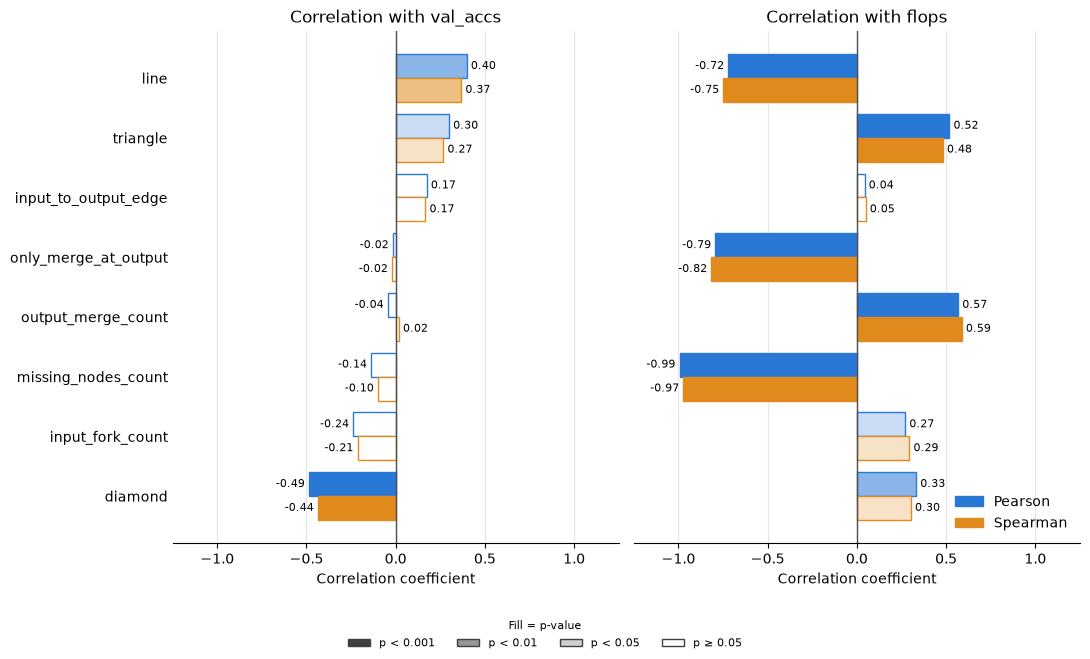

pearson                                    spearman  \
                      val_accs               flops                val_accs   
                             r         p         r             p         r   
diamond              -0.485567  0.000084  0.331889  9.580799e-03 -0.435737   
input_fork_count     -0.237901  0.067192  0.270450  3.662270e-02 -0.213863   
missing_nodes_count  -0.137389  0.295193 -0.993474  2.165295e-56 -0.099181   
output_merge_count   -0.043980  0.738633  0.567127  2.306722e-06  0.017411   
only_merge_at_output -0.015853  0.904309 -0.793238  4.158283e-14 -0.020427   
input_to_output_edge  0.173792  0.184178  0.042847  7.451355e-01  0.166145   
triangle              0.298806  0.020389  0.517975  2.247994e-05  0.266618   
line                  0.397955  0.001639 -0.720348  8.691921e-11  0.367099   

                                                        
                                   flops                
                             p         r             p  
diamond               0.000502  0.302415  1.884899e-02  
input_fork_count      0.100845  0.293830  2.268660e-02  
missing_nodes_count   0.450876 -0.972209  2.863959e-38  
output_merge_count    0.894957  0.587389  8.074520e-07  
only_merge_at_output  0.876890 -0.815411  2.155847e-15  
input_to_output_edge  0.204541  0.049009  7.099997e-01  
triangle              0.039475  0.481200  9.940146e-05  
line                  0.003912 -0.747632  6.747792e-12

In [26]:
from matplotlib.colors import to_rgb
from scipy import stats

CORR_TESTS = {"pearson": stats.pearsonr, "spearman": stats.spearmanr, "kendall": stats.kendalltau}


# Colour strength per p-value range, strongest evidence first; anything above the
# last cutoff is not significant and is drawn as a hollow outline
P_SHADES = [(0.001, 1.0), (0.01, 0.55), (0.05, 0.25)]


def _p_fill(color, p):
    strength = next((s for cutoff, s in P_SHADES if p < cutoff), 0.0)
    # Blend towards white instead of using alpha so the grid does not show through
    return tuple(1 - strength * (1 - channel) for channel in to_rgb(color))


def plot_feature_correlations(df, targets=("val_accs", "flops"),
                              exclude=("arch", "generation"),
                              methods=("pearson", "spearman", "kendall")):
    targets = list(targets)
    methods = [methods] if isinstance(methods, str) else list(methods)
    numeric = df.select_dtypes(include=["number", "bool"]).astype(float)
    features = [c for c in numeric.columns
                if c not in targets and c not in exclude and numeric[c].nunique() > 1]

    # Columns are (method, target, "r" | "p")
    table = {}
    for method in methods:
        for target in targets:
            r, p = [], []
            for feature in features:
                pair = numeric[[feature, target]].dropna()
                res = CORR_TESTS[method](pair[feature], pair[target])
                r.append(res[0])
                p.append(res[1])
            table[(method, target, "r")] = r
            table[(method, target, "p")] = p
    corr = pd.DataFrame(table, index=features)
    # Same feature order in every panel, sorted by the first method and target
    corr = corr.sort_values((methods[0], targets[0], "r"))

    method_colors = dict(zip(methods, ["#2a78d6", "#e08a1e", "#3a9d5d"]))
    bar_height = 0.8 / len(methods)
    y = np.arange(len(features))

    fig, axes = plt.subplots(1, len(targets), sharey=True, squeeze=False,
                             figsize=(5.5 * len(targets),
                                      0.3 * len(features) * len(methods) + 1.8))
    axes = axes[0]
    for ax, target in zip(axes, targets):
        for i, method in enumerate(methods):
            r = corr[(method, target, "r")]
            p = corr[(method, target, "p")]
            # First method on top within each feature group
            offset = ((len(methods) - 1) / 2 - i) * bar_height
            # Darker fill = smaller p-value; the outline keeps pale and hollow bars readable
            bars = ax.barh(y + offset, r, height=bar_height, label=method.capitalize(),
                           color=[_p_fill(method_colors[method], pv) for pv in p],
                           edgecolor=method_colors[method], linewidth=1)
            ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
        ax.axvline(0, color="0.3", linewidth=1)
        ax.set_xlim(-1.25, 1.25)
        ax.set_yticks(y, corr.index)
        ax.set_title(f"Correlation with {target}")
        ax.set_xlabel("Correlation coefficient")
        ax.grid(axis="x", color="0.9", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.tick_params(axis="y", length=0)
    # Explicit handles so the legend is not shaded along with the bars
    axes[-1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=method_colors[m]) for m in methods],
                    labels=[m.capitalize() for m in methods], frameon=False, loc="lower right")

    cutoffs = [cutoff for cutoff, _ in P_SHADES]
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=_p_fill("0.25", pv), edgecolor="0.25")
                        for pv in [0] + cutoffs],
               labels=[f"p < {cutoff:g}" for cutoff in cutoffs] + [f"p ≥ {cutoffs[-1]:g}"],
               title="Fill = p-value", title_fontsize=8, fontsize=8, ncol=len(cutoffs) + 1,
               frameon=False, loc="lower center")
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()
    return corr
plot_feature_correlations(result_df, targets=("val_accs", "flops"), exclude=("arch", "generation"), methods=("pearson", "spearman"))


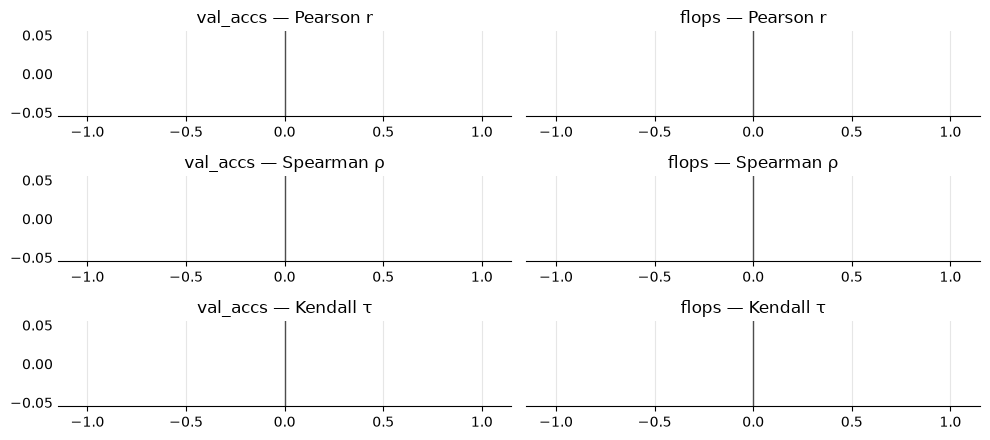

Empty DataFrame
Columns: [(pearson, val_accs), (pearson, flops), (spearman, val_accs), (spearman, flops), (kendall, val_accs), (kendall, flops)]
Index: []

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

METHOD_LABELS = {
    "pearson": "Pearson r",
    "spearman": "Spearman ρ",
    "kendall": "Kendall τ",
    "mutual_info": "Mutual information (nats)",
}


def plot_feature_correlations(df, targets=("val_accs", "flops"),
                              methods=("pearson", "spearman", "kendall"),
                              exclude=("arch", "generation")):
    targets = list(targets)
    methods = [methods] if isinstance(methods, str) else list(methods)
    unknown = set(methods) - set(METHOD_LABELS)
    if unknown:
        raise ValueError(f"Unknown method(s) {sorted(unknown)}; choose from {list(METHOD_LABELS)}")

    numeric = df.select_dtypes(include=["number", "bool"]).astype(float)
    features = [c for c in numeric.columns
                if c not in targets and c not in exclude and numeric[c].nunique() > 1]

    results = {}
    for method in methods:
        if method == "mutual_info":
            from sklearn.feature_selection import mutual_info_regression
            clean = numeric[features + targets].dropna()
            results[method] = pd.DataFrame(
                {t: mutual_info_regression(clean[features], clean[t], random_state=0)
                 for t in targets}, index=features)
        else:
            results[method] = numeric[features + targets].corr(method=method).loc[features, targets]

    # Same feature order in every panel, sorted by the first method and target
    order = results[methods[0]][targets[0]].sort_values().index
    corr = pd.concat({m: r.loc[order] for m, r in results.items()}, axis=1)

    fig, axes = plt.subplots(len(methods), len(targets), sharey=True, squeeze=False,
                             figsize=(5 * len(targets),
                                      (0.4 * len(features) + 1.5) * len(methods)))
    for row, method in zip(axes, methods):
        for ax, target in zip(row, targets):
            values = corr[(method, target)]
            colors = ["#2a78d6" if v >= 0 else "#d9483b" for v in values]
            bars = ax.barh(values.index, values, color=colors, height=0.6)
            ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
            if method == "mutual_info":
                # Mutual information is non-negative and has no fixed upper bound
                ax.set_xlim(0, max(corr[method].max().max(), 1e-9) * 1.2)
            else:
                ax.axvline(0, color="0.3", linewidth=1)
                ax.set_xlim(-1.15, 1.15)
            ax.set_title(f"{target} — {METHOD_LABELS[method]}")
            ax.grid(axis="x", color="0.9", linewidth=0.8)
            ax.set_axisbelow(True)
            ax.spines[["top", "right", "left"]].set_visible(False)
            ax.tick_params(axis="y", length=0)

    fig.tight_layout()
    plt.show()
    return corr
plot_feature_correlations(result_df, targets=("val_accs", "flops"), exclude=("arch", "generation"), methods=("pearson", "spearman", "kendall"))

In [14]:
result_df.head()

,arch,val_accs,generation,flops,triangle,diamond,line,only_merge_at_output,input_to_output_edge,output_merge_count,input_fork_count,missing_nodes_count,num_phases
0,0,63.15,0,58.9752,1,2,3,2,2,1.75,1.75,4,4
1,1,62.23,0,77.2315,3,4,1,0,4,2.00,2.50,0,4
2,2,62.97,0,47.8521,0,0,2,4,3,2.25,1.75,5,4
3,3,63.35,0,72.0380,2,3,0,1,4,2.25,3.00,1,4
4,4,62.68,0,59.5637,0,2,1,2,2,2.25,2.00,3,4


Explained variance ratio (PC1, PC2): [0.29019918 0.13118232]
Total variance captured: 42.14%


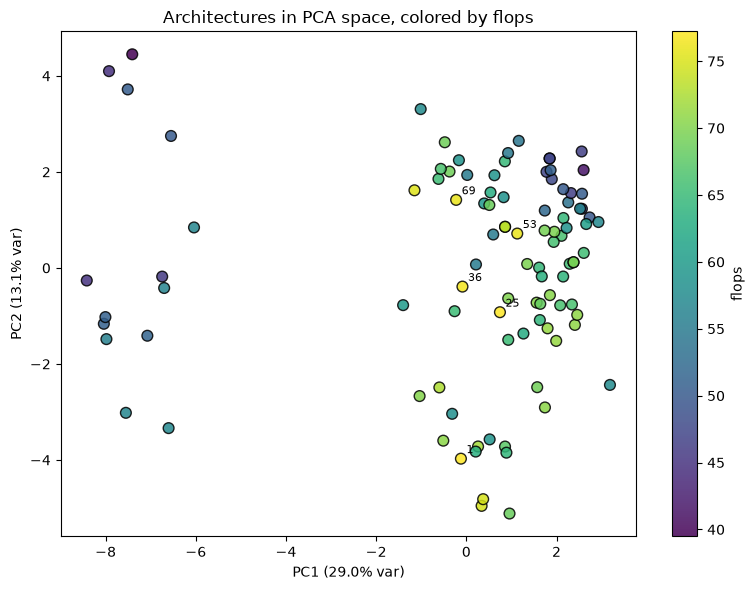


Top features driving flops:
phase0_missing_nodes_count     0.481559
phase0_only_merge_at_output    0.139295
phase2_missing_nodes_count     0.105690
phase1_missing_nodes_count     0.057017
phase3_triangle                0.032836
phase3_missing_nodes_count     0.030728
generation                     0.029833
phase3_output_merge_count      0.017896
phase3_line                    0.011677
phase3_diamond                 0.011426
phase2_input_fork_count        0.008132
phase2_output_merge_count      0.007604
phase1_output_merge_count      0.006888
phase3_only_merge_at_output    0.006714
phase0_triangle                0.005248
dtype: float64


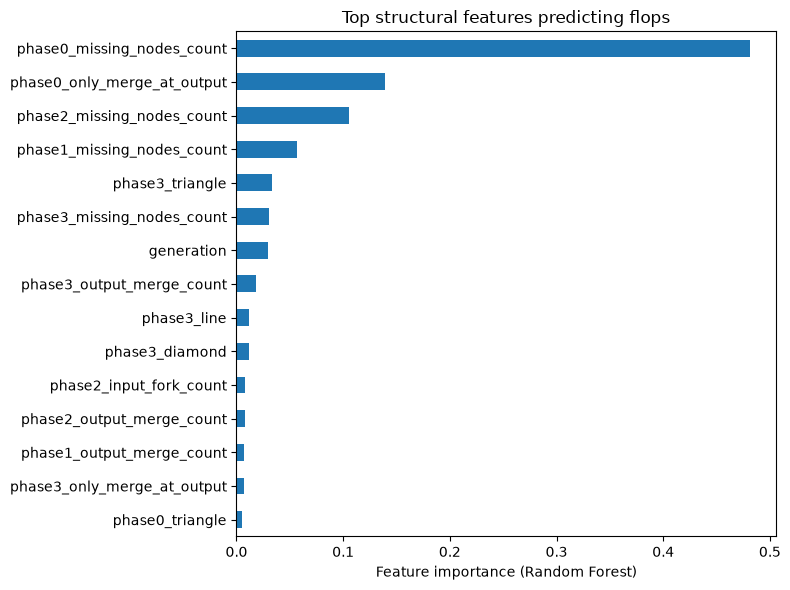

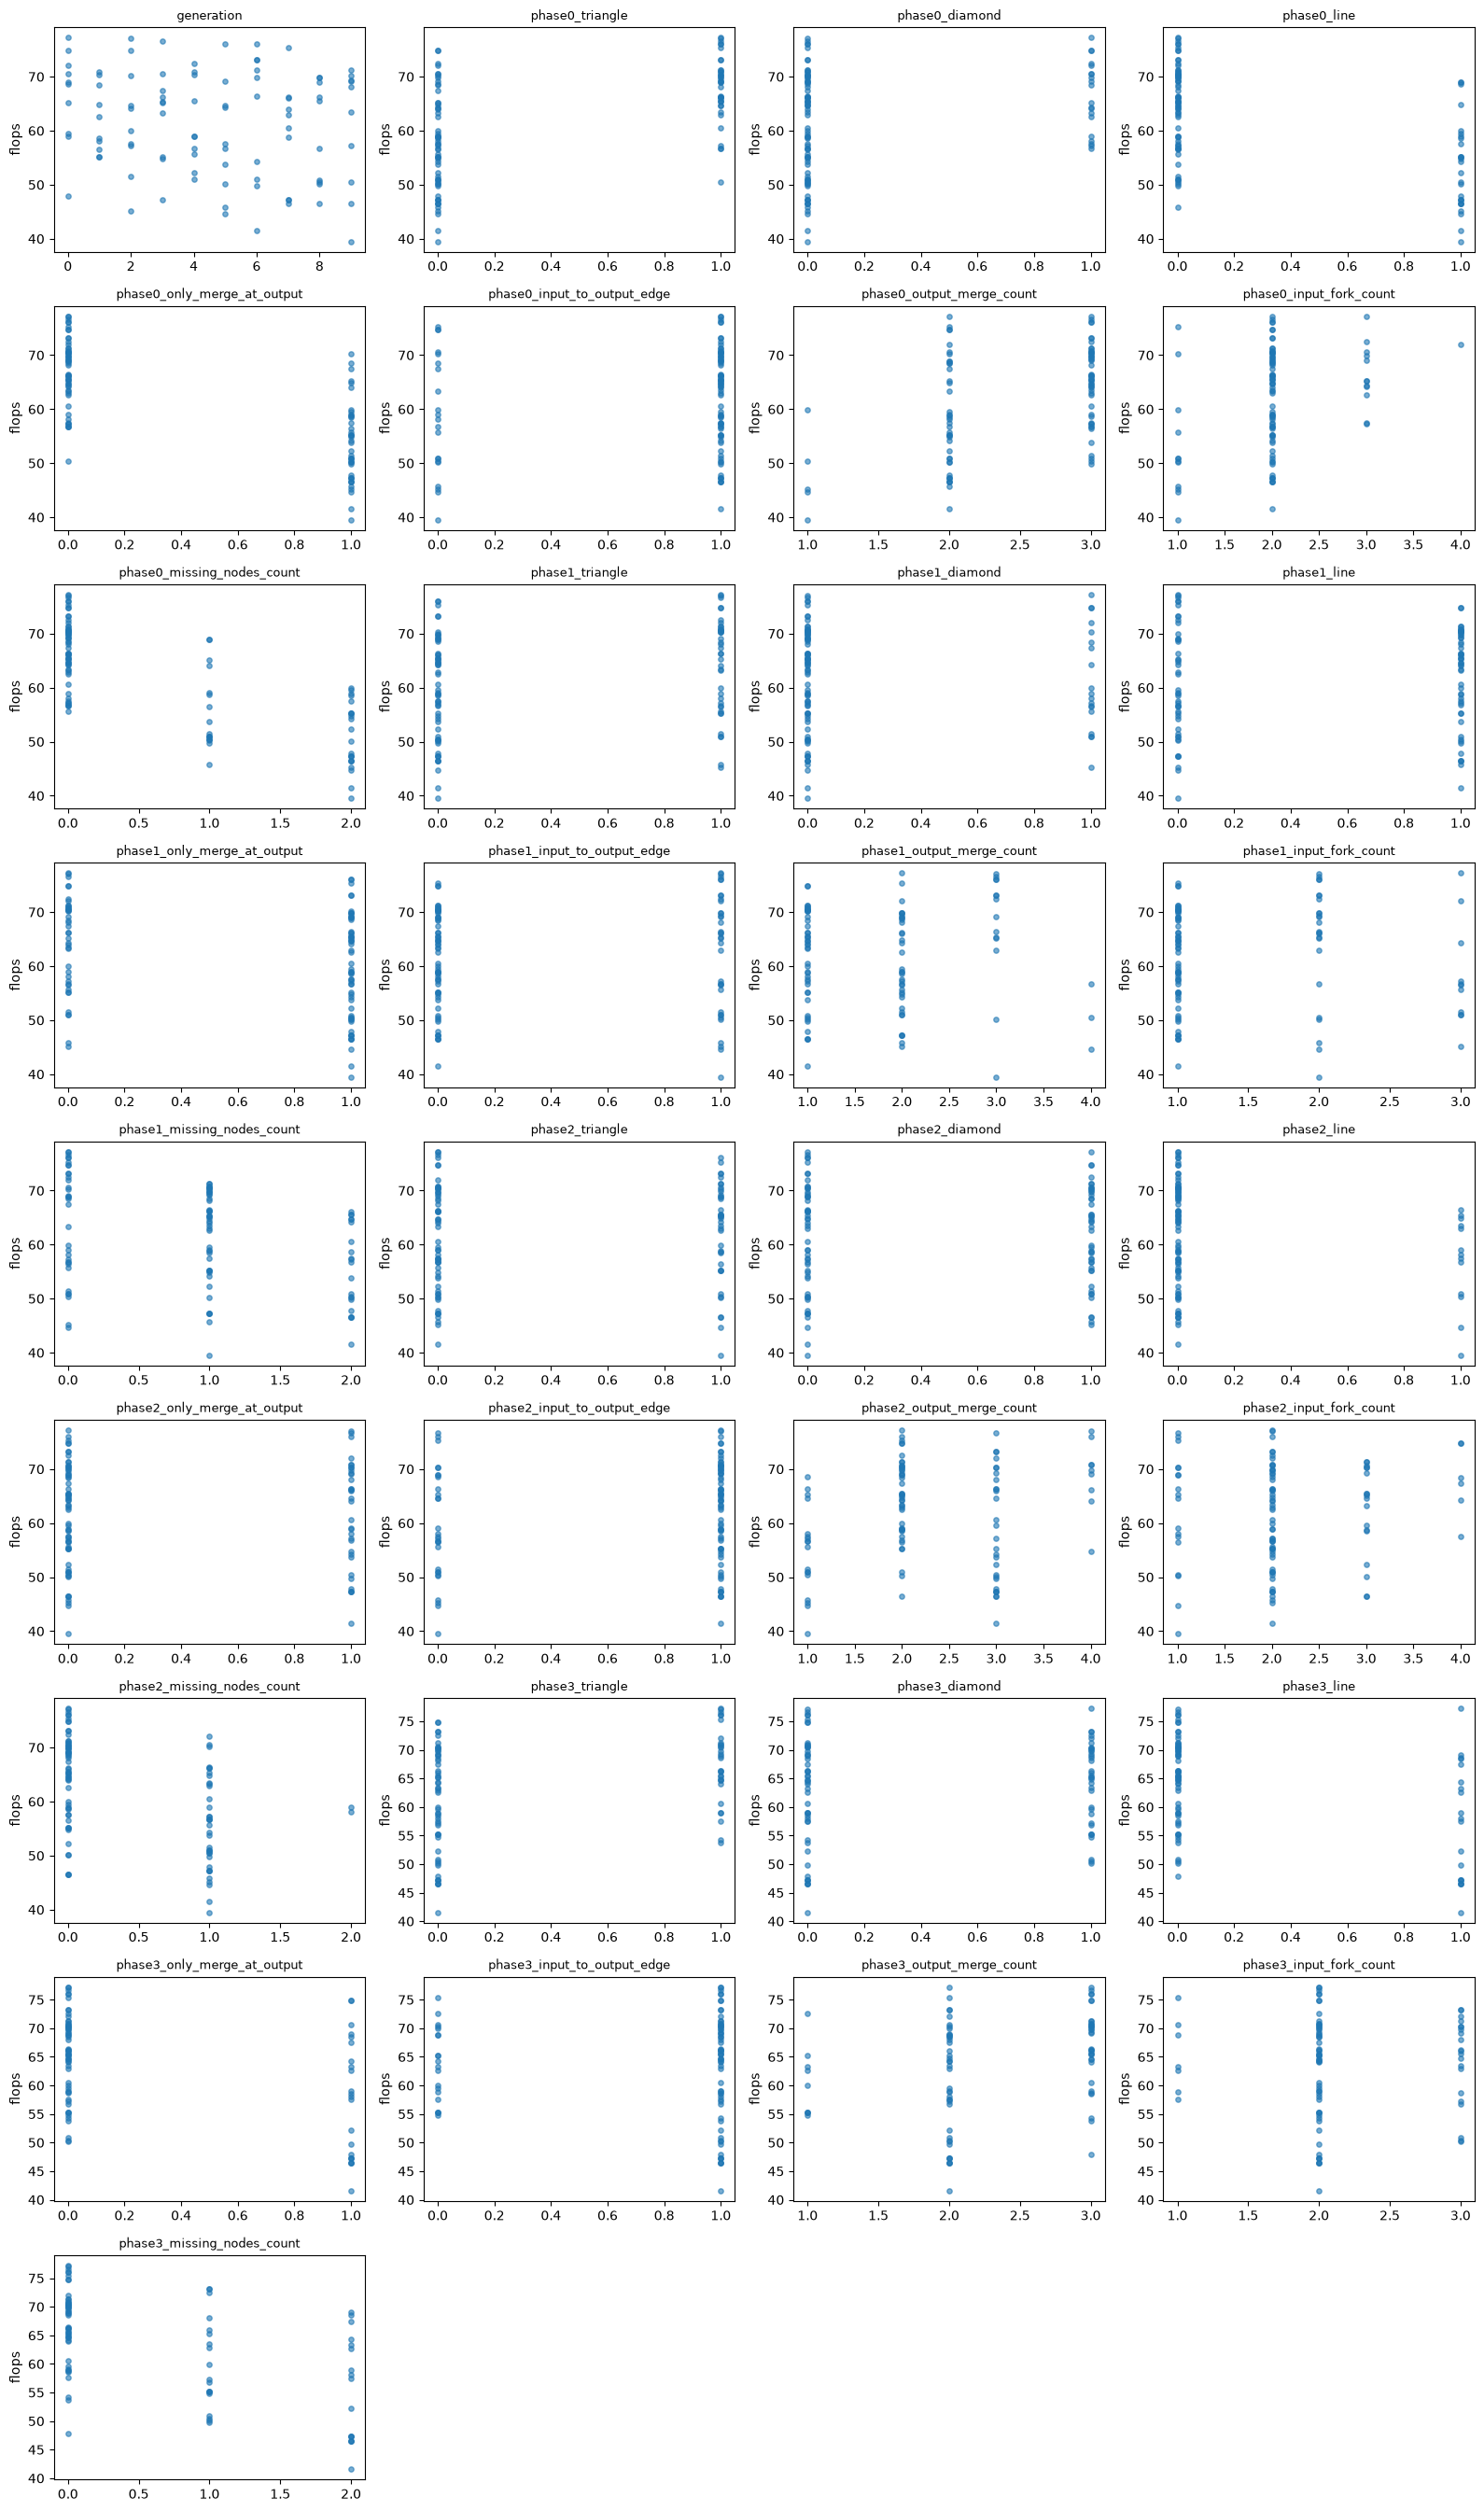

{'X':     generation phase0_triangle phase0_diamond phase0_line  \
 0            0               0              1           0   
 1            0               1              1           0   
 2            0               0              0           1   
 3            0               0              1           0   
 4            0               0              0           1   
 ..         ...             ...            ...         ...   
 95           9               1              0           0   
 96           9               1              0           0   
 97           9               1              0           0   
 98           9               1              0           0   
 99           9               1              0           0   
 
    phase0_only_merge_at_output phase0_input_to_output_edge  \
 0                            0                           0   
 1                            0                           1   
 2                            1                           1 

In [21]:
analyze_features(result_df,target_col="flops", save_plots=False)

In [24]:
result_df.groupby('generation')['flops'].max()

generation
0    77.2315
1    70.8332
2    77.0864
3    76.6348
4    72.5147
5    76.0496
6    76.0496
7    75.3445
8    69.7964
9    71.2848
Name: flops, dtype: float64

In [8]:
result_df.head()

,arch,val_accs,generation,phase0_triangle,phase0_diamond,phase0_line,phase0_only_merge_at_output,phase0_input_to_output_edge,phase0_output_merge_count,phase0_input_fork_count,...,phase2_input_fork_count,phase2_missing_nodes_count,phase3_triangle,phase3_diamond,phase3_line,phase3_only_merge_at_output,phase3_input_to_output_edge,phase3_output_merge_count,phase3_input_fork_count,phase3_missing_nodes_count
0,0,63.15,0,0,1,0,0,0,2,2,...,2,2,0,0,1,1,1,2.0,2.0,2.0
1,1,62.23,0,1,1,0,0,1,2,3,...,2,0,1,1,1,0,1,2.0,2.0,0.0
2,2,62.97,0,0,0,1,1,1,2,2,...,2,1,0,0,0,1,1,3.0,2.0,0.0
3,3,63.35,0,0,1,0,0,1,2,4,...,2,1,1,1,0,0,1,2.0,3.0,0.0
4,4,62.68,0,0,0,1,1,1,2,2,...,3,0,0,1,0,0,0,2.0,2.0,0.0


Top architecture per generation:
            arch    flops
generation               
0              1  77.2315
1             15  70.8332
2             25  77.0864
3             36  76.6348
4             49  72.5147
5             53  76.0496
6             69  76.0496
7             78  75.3445
8             83  69.7964
9             95  71.2848

Feature continuity across winning architectures (1.0 = always present in the top model, 0.0 = never):
val_accs                       1.0
phase0_input_fork_count        1.0
phase0_output_merge_count      1.0
phase1_output_merge_count      1.0
phase1_input_fork_count        1.0
phase3_input_fork_count        1.0
phase3_output_merge_count      1.0
phase2_output_merge_count      1.0
phase2_input_fork_count        1.0
phase0_triangle                0.9
phase0_input_to_output_edge    0.9
phase3_triangle                0.9
phase3_input_to_output_edge    0.8
phase1_input_to_output_edge    0.7
phase2_input_to_output_edge    0.7
phase1_triangle            

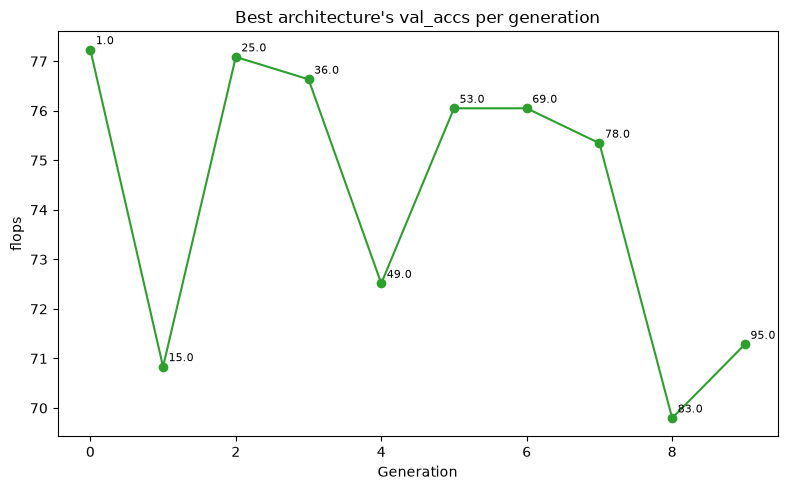

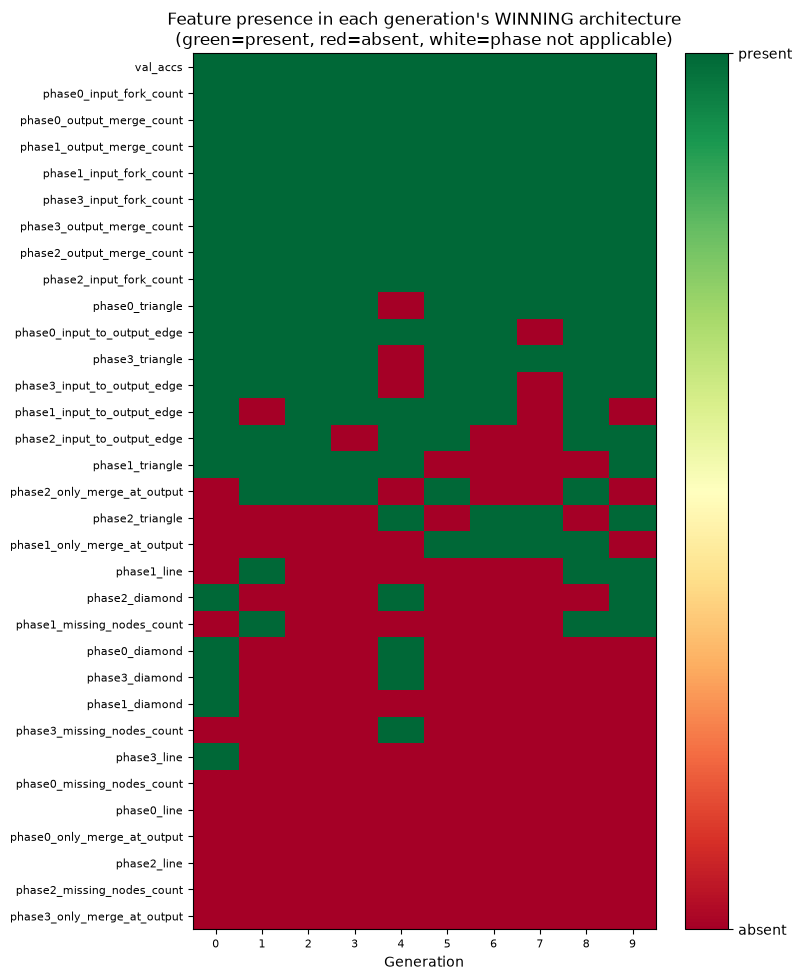

{'top_per_gen':             arch  val_accs    flops  phase0_triangle  phase0_diamond  \
 generation                                                             
 0              1     62.23  77.2315                1               1   
 1             15     63.57  70.8332                1               0   
 2             25     64.06  77.0864                1               0   
 3             36     64.06  76.6348                1               0   
 4             49     63.06  72.5147                0               1   
 5             53     64.13  76.0496                1               0   
 6             69     63.54  76.0496                1               0   
 7             78     60.93  75.3445                1               0   
 8             83     63.96  69.7964                1               0   
 9             95     63.88  71.2848                1               0   
 
             phase0_line  phase0_only_merge_at_output  \
 generation                                       

In [34]:
analyze_top_model_lineage(result_df, val_col="flops", save_plots=False)

Correlation of feature's per-generation mean with val_accs per-generation mean (overall population):
phase2_output_merge_count      0.823154
phase2_missing_nodes_count    -0.665180
phase1_diamond                 0.628749
phase2_input_to_output_edge    0.530221
phase3_diamond                -0.424512
phase3_input_fork_count       -0.409023
phase1_missing_nodes_count    -0.364462
phase2_triangle                0.364284
phase0_line                   -0.325554
phase1_output_merge_count      0.269308
phase3_output_merge_count      0.264584
phase3_line                    0.261411
dtype: float64

Same, computed only over top performers per generation (elite persistence):
phase3_triangle                0.745424
phase0_triangle                0.712840
phase2_input_fork_count       -0.706997
phase3_only_merge_at_output   -0.589067
phase3_missing_nodes_count    -0.589067
phase3_input_to_output_edge    0.589067
phase0_input_to_output_edge    0.544624
phase1_input_fork_count        0.539308
phase2_

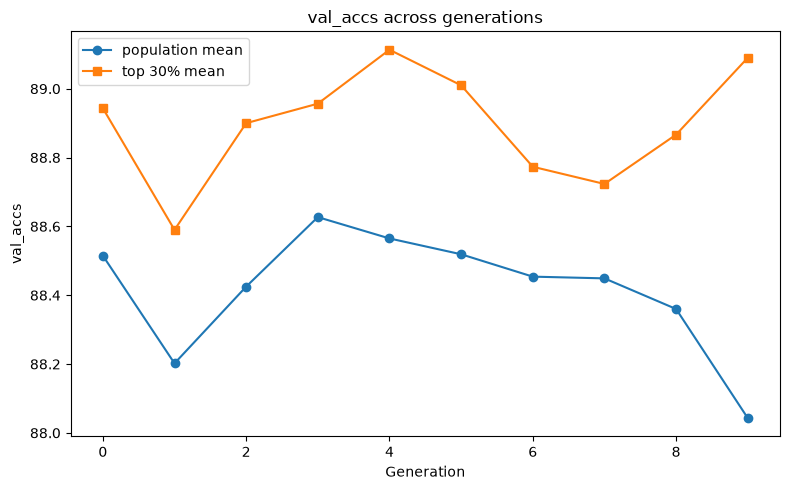

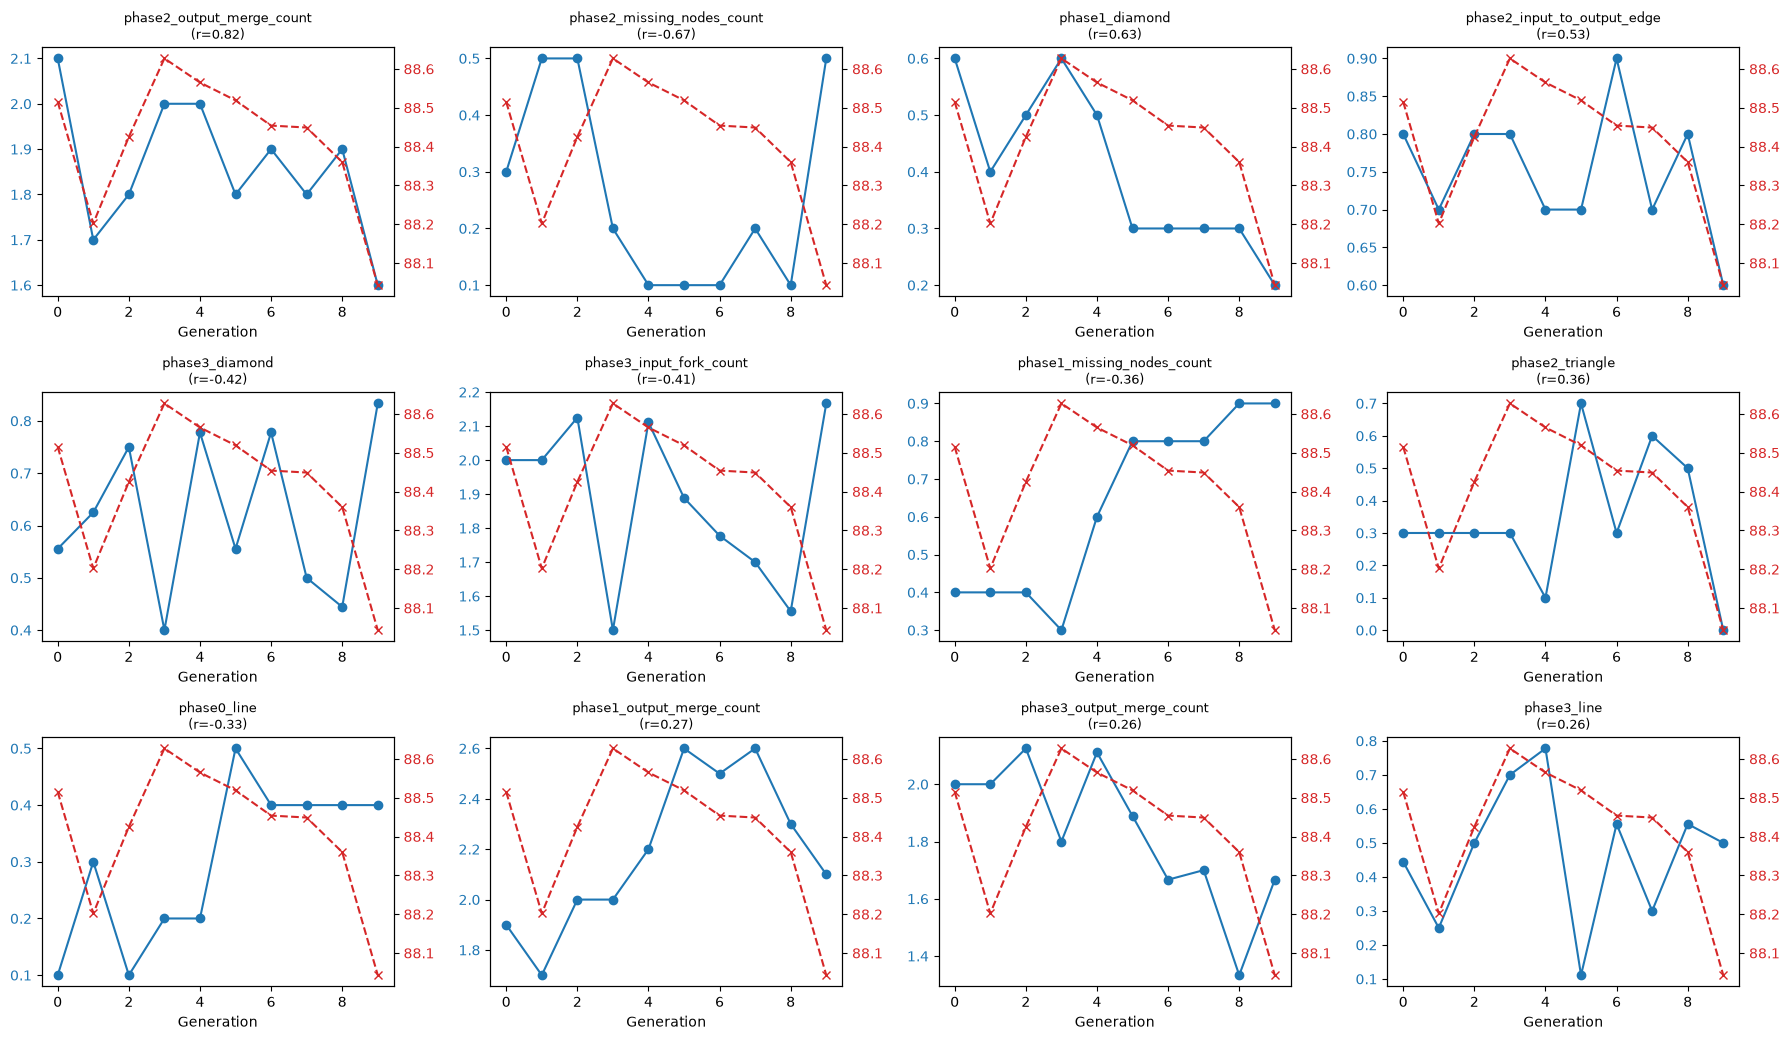

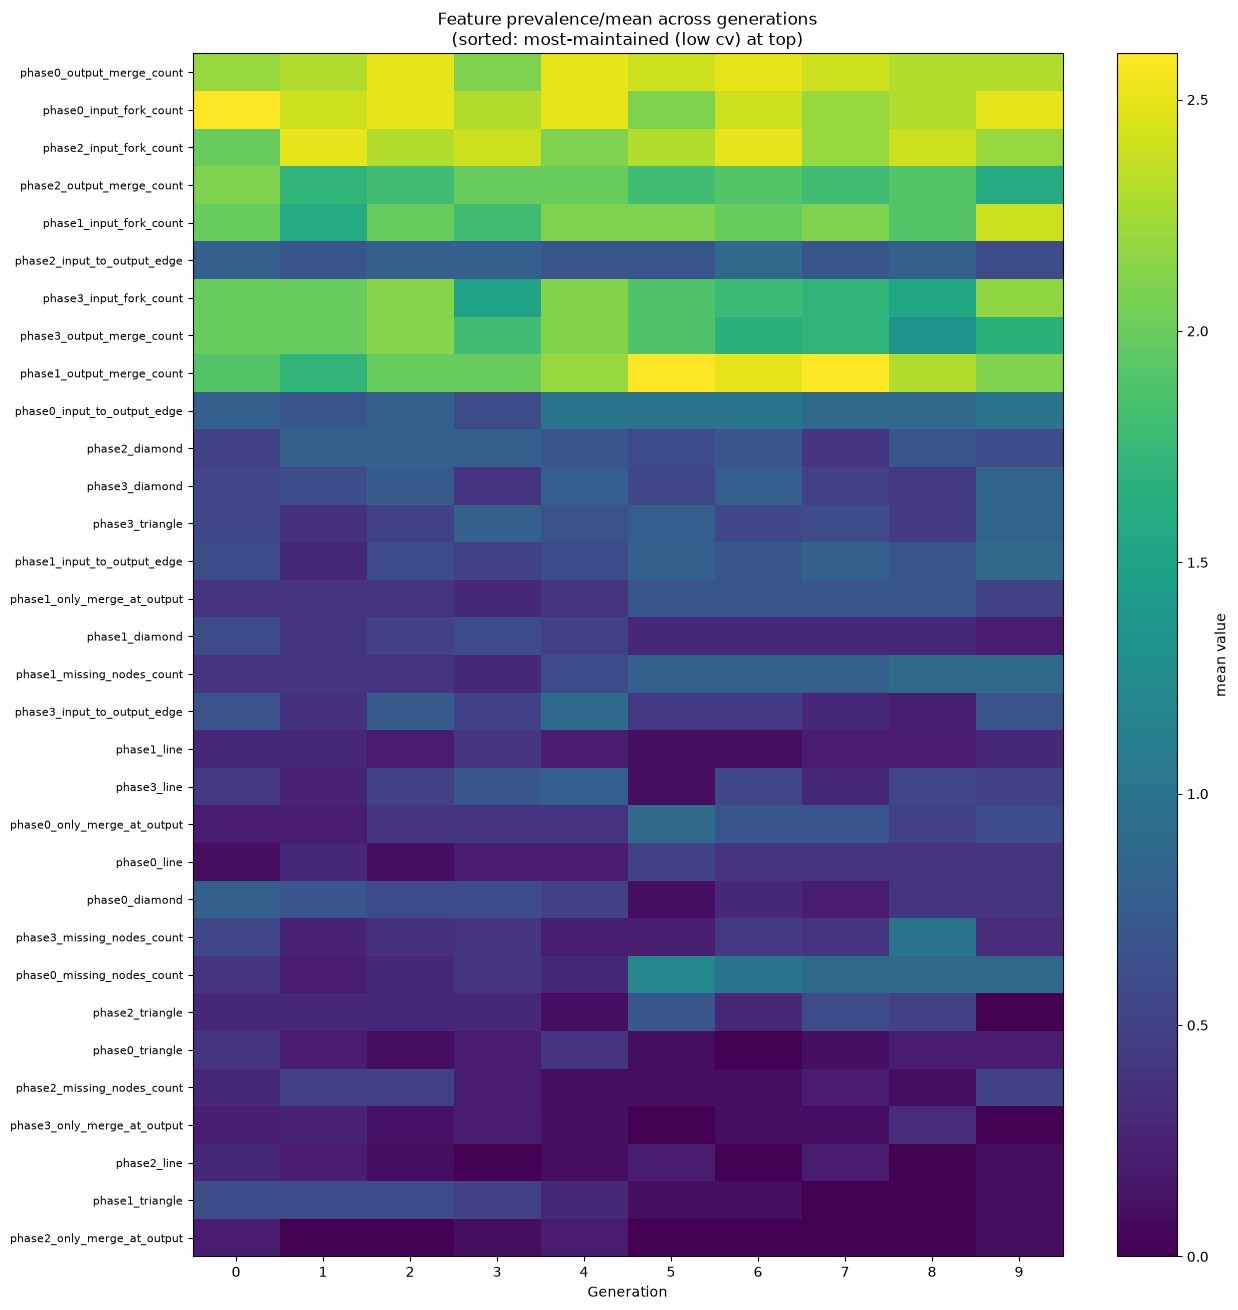

{'gen_means':             phase0_triangle  phase0_diamond  phase0_line  \
 generation                                                 
 0                       0.4             0.8          0.1   
 1                       0.2             0.7          0.3   
 2                       0.1             0.6          0.1   
 3                       0.2             0.6          0.2   
 4                       0.4             0.5          0.2   
 5                       0.1             0.1          0.5   
 6                       0.0             0.3          0.4   
 7                       0.1             0.2          0.4   
 8                       0.2             0.4          0.4   
 9                       0.2             0.4          0.4   
 
             phase0_only_merge_at_output  phase0_input_to_output_edge  \
 generation                                                             
 0                                   0.2                          0.8   
 1                                

In [58]:
analyze_generational_trends(result_df, save_plots=False)


# Previous Codes

In [7]:
def extract_architecture_df(base_dir):
    """
    Extract architecture information from arch_*/log.txt files.

    Parameters
    ----------
    base_dir : str
        Directory containing arch_* folders.

    Returns
    -------
    pd.DataFrame
        Columns:
        ['arch', 'genome', 'architecture',
         'param_size', 'flops', 'valid_acc']
    """

    rows = []

    for folder in os.listdir(base_dir):

        if not folder.startswith("arch_"):
            continue

        log_path = os.path.join(base_dir, folder, "log.txt")

        if not os.path.isfile(log_path):
            continue

        with open(log_path, "r") as f:
            content = f.read()

        row = {
            "arch": folder.split("_")[1],
            "genome": None,
            "architecture": None,
            "param_size": None,
            "flops": None,
            "valid_acc": None,
        }

        genome_match = re.search(
            r"Genome\s*=\s*(.+)",
            content
        )
        if genome_match:
            row["genome"] = ast.literal_eval(genome_match.group(1).strip())

        architecture_match = re.search(
            r"Architecture\s*=\s*(.+)",
            content
        )
        if architecture_match:
            row["architecture"] = ast.literal_eval(
                architecture_match.group(1).strip()
            )

        param_match = re.search(
            r"param size\s*=\s*([\d.]+)",
            content
        )
        if param_match:
            row["param_size"] = float(param_match.group(1))

        flops_match = re.search(
            r"flops\s*=\s*([\d.]+)",
            content
        )
        if flops_match:
            row["flops"] = float(flops_match.group(1))

        acc_match = re.search(
            r"valid_acc\s*=\s*([\d.]+)",
            content
        )
        if acc_match:
            row["valid_acc"] = float(acc_match.group(1))

        rows.append(row)

    df = pd.DataFrame(rows)

    # Sort by architecture number
    if not df.empty:
        df["arch"] = df["arch"].astype(int)  # Ensure 'arch' is string type
        
        # df = (
        #     df.assign(
        #         arch_num=df["arch"].str.extract(r"(\d+)").astype(int)
        #     )
        #     .sort_values("arch_num")
        #     .drop(columns="arch_num")
        #     .reset_index(drop=True)
        # )

    return df

def read_file(file):
    df = pd.read_csv(file)
    print(f"Rows: {len(df)}, Cols: {len(df.columns)}")
    return df

def read_files(files):
    dfs=[]
    for i, file in enumerate(data_paths):
        print(f"File {i+1}: ", end="")
        df = read_file(file)        
        intensities = {'14': 'low', '15': 'med', '16':'high'}
        # category = file.split("_")[0].split("/")[-1] # extract the beam intensity 
        category = Path(file).name.split("_", 1)[0]
        df['run'] = i # create a run for each separate file
        df['type'] = intensities[category]
        df['id'] = df['type'].astype(str) + '-' + df['arch'].astype(str) 

        # df['architecture'] = df['architecture'].apply(literal_eval)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

In [5]:
df = read_files(data_paths)

NameError: name 'read_files' is not defined

In [4]:
df.head()

NameError: name 'df' is not defined

In [9]:
base_dir = '/media/volume/a4nn-ap-volume/PD_Data/models/gpu1/no_early_termination/classification-search-penguin-pd_exv100_1gpu_25e_1e14-macro-20230328-061437/'
df1 = extract_architecture_df(base_dir)

In [10]:
cols_to_add = ["arch","architecture","param_size","valid_acc"]
df_merged = df.merge(df1[cols_to_add],on="arch",how="left")

In [11]:
df_merged.head()

,epoch,train_accs,val_accs,predictions,converged,genome,arch,flops,run,type,id,architecture,param_size,valid_acc
0,0,80.800844,59.889141,inf,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ...",0.33401,97.543462
1,1,88.294388,52.154195,inf,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ...",0.33401,97.543462
2,2,90.949172,83.900227,inf,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ...",0.33401,97.543462
3,3,92.906405,61.098513,71.543131,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ...",0.33401,97.543462
4,4,94.383385,70.515243,71.913331,False,"[[0, 0, 0, 1, 1, 0, 1], [0, 0, 0, 0, 0, 1, 0],...",68,715.4103,0,low,low-68,"[[[0], [0, 0], [1, 1, 0], [1]], [[0], [0, 0], ...",0.33401,97.543462


In [12]:
beam_intensity = "low"
subdf = df_merged.loc[df_merged['type']==beam_intensity].reset_index(drop=True)
# Keep only the last checkpoint for each architecture
subdf = (
    subdf
    .sort_values(['arch', 'epoch'], ascending=[True, True]) # sort by architecture and epoch
    .drop_duplicates(subset='arch', keep='last', ignore_index=True) # drop duplicates and keep last epoch
)

subdf["dag"] = subdf['architecture'].apply(lambda x: from_edgelist_to_nx(build_genome_edgelist(x), create_using='directed'))

35


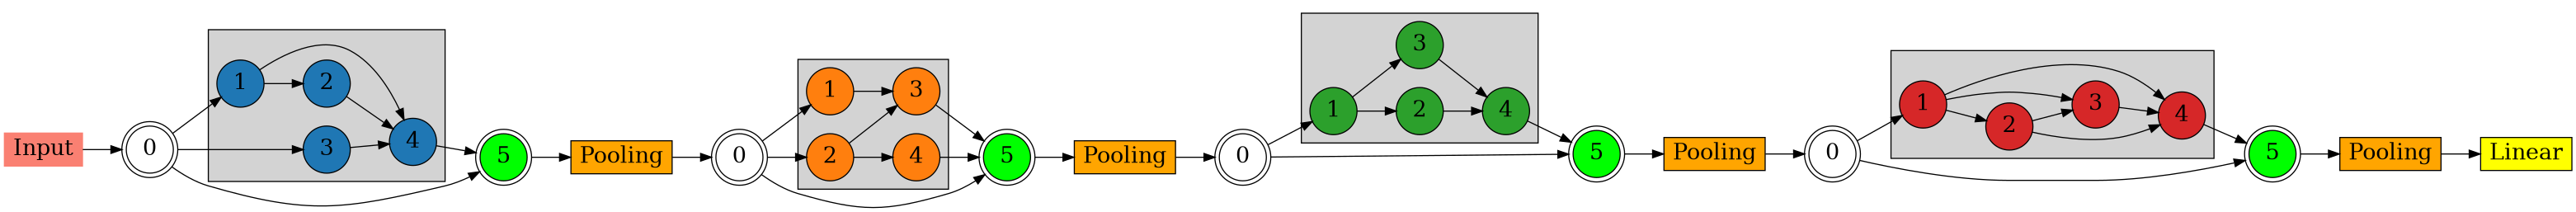

In [37]:
genomes = subdf.architecture.to_list()
# Select a random architecture
arch_id = np.random.randint(0, len(genomes), size=1).item()
print(arch_id)

genome = genomes[arch_id]
# Arguments for visualization purposes
kwargs = {
    'title': None, # title for a graph
    'rankdir': 'LR', # :param set direction of graph layout https://graphviz.org/docs/attrs/rankdir/
    'phase_background_color': 'lightgray', # param: the background color for each phase
    'node_shape': 'circle', # :param shape of computational units
    'pool_shape': 'box', # :param shape of pooling layer
    'io_shape': 'doublecircle', # :param shape of input and output nodes
    'linear_shape': 'box', # :param shape of linear layer
    'node_cmap': 'tab10', # :param string name of matplotlib supported colormaps
    'pool_color': 'orange', # :param color for pooling layers
    'fc_color': 'yellow', # :param color for linear layer
    'output_color': 'green', # :param color for output nodes
    'input_color': 'white', # :param color for input nodes
}

dot = build_pydot_genome(genome, **kwargs)
view_pydot(dot)

In [38]:
analyzer = EvoGraphAnalyzer(genomes_nx[14])
rows = analyzer.feature_table()
rows

NameError: name 'genomes_nx' is not defined

# Genomes to NetworkX

In [15]:
subdf.head()

,epoch,train_accs,val_accs,predictions,converged,genome,arch,flops,run,type,id,architecture,param_size,valid_acc,dag
0,24,99.952762,94.053918,97.853167,True,"[[1, 0, 1, 1, 1, 0, 1], [0, 0, 0, 0, 0, 0, 0],...",0,740.0186,0,low,low-0,"[[[1], [0, 1], [1, 1, 0], [1]], [[0], [0, 0], ...",0.117962,94.053918,"(phase_0_node_0, phase_0_node_1, phase_0_node_..."
1,24,100.000000,95.616024,98.419161,False,"[[0, 1, 1, 0, 0, 0, 0], [1, 1, 0, 1, 0, 0, 1],...",1,893.3620,0,low,low-1,"[[[0], [1, 1], [0, 0, 0], [0]], [[1], [1, 0], ...",0.383738,95.616024,"(phase_0_node_0, phase_0_node_1, phase_0_node_..."
2,24,100.000000,97.996977,98.225477,True,"[[1, 1, 0, 1, 1, 1, 1], [0, 0, 1, 0, 0, 1, 0],...",2,993.3537,0,low,low-2,"[[[1], [1, 0], [1, 1, 1], [1]], [[0], [0, 1], ...",0.471434,97.996977,"(phase_0_node_0, phase_0_node_1, phase_0_node_..."
3,24,99.721295,94.375157,96.611387,True,"[[1, 0, 1, 1, 0, 1, 1], [0, 0, 0, 0, 0, 0, 1],...",3,731.0186,0,low,low-3,"[[[1], [0, 1], [1, 0, 1], [1]], [[0], [0, 0], ...",0.117386,94.375157,"(phase_0_node_0, phase_0_node_1, phase_0_node_..."
4,24,99.996851,98.015873,101.543724,False,"[[0, 0, 1, 0, 0, 0, 1], [1, 0, 1, 1, 0, 1, 1],...",4,917.7927,0,low,low-4,"[[[0], [0, 1], [0, 0, 0], [1]], [[1], [0, 1], ...",0.489290,98.015873,"(phase_0_node_0, phase_0_node_2, phase_0_node_..."


In [49]:
subdf.iloc[0].dag

In [16]:
genomes_nx = [from_edgelist_to_nx(build_genome_edgelist(i), create_using='directed') for i in genomes]

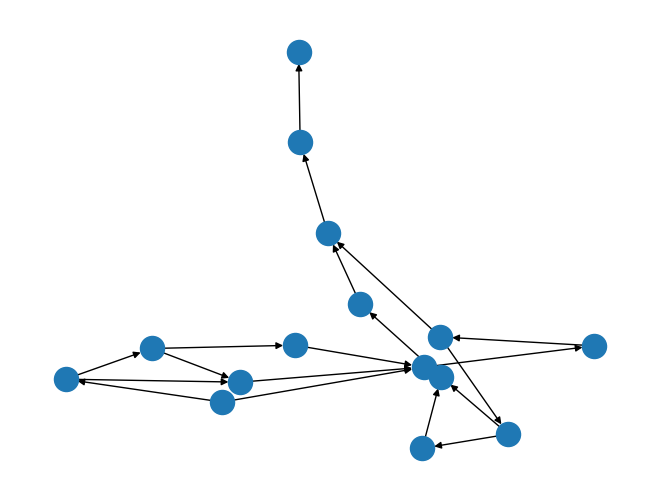

In [17]:
nx.draw(genomes_nx[0])

# Model Visualiztion

In [16]:
res

{'max_phases': {'value': 3, 'graph_idx': 1},
 'max_nodes_in_phase': {'value': 7, 'graph_idx': 0, 'phase': 0},
 'max_edges_in_phase': {'value': 9, 'graph_idx': 0, 'phase': 0},
 'max_node0_degree': {'value': 4, 'graph_idx': 2, 'phase': 2}}

If 0->5, Diamond, Line, Missing Nodes, Triangle, indeg 5, Outdeg 0, Fork No join
Updates required: Fork No Join: incorrect, 

In [20]:
analyzer = EvoGraphAnalyzer(genomes_nx[82])
rows = analyzer.feature_table()

In [39]:
import pandas as pd

def flatten_event(phases):
    row = {}

    for phase_data in phases:
        phase = phase_data["phase"]

        for key, value in phase_data.items():
            if key == "phase":
                continue

            # Convert missing_nodes into useful numeric features
            if key == "missing_nodes":
                row[f"phase{phase}_missing_nodes_count"] = len(value)

                # for node in value:
                #     row[f"phase{phase}_missing_node_{node}"] = 1
            else:
                row[f"phase{phase}_{key}"] = value

    return row


all_rows = []

for genome in subdf["dag"]:
    phases = EvoGraphAnalyzer(genome).feature_table()
    all_rows.append(flatten_event(phases))

features_df = pd.DataFrame(all_rows, index=subdf.index)

result_df = pd.concat(
    [
        subdf[["arch", "val_accs"]],  # use "valid_acc" if that is the actual column name
        features_df,
    ],
    axis=1,
)

# bool_cols = result_df.select_dtypes(include="bool").columns
# result_df[bool_cols] = result_df[bool_cols].fillna(False).astype("int64")

# num_cols = result_df.select_dtypes(include="number").columns
# result_df[num_cols] = result_df[num_cols].apply(
#     pd.to_numeric, errors="coerce"
# ).fillna(0)
# Convert True/False to 1/0 while preserving NaN values
result_df = result_df.replace({True: 1, False: 0})

print(result_df.shape)
display(result_df.head())

(100, 34)


,arch,val_accs,phase0_triangle,phase0_diamond,phase0_line,phase0_only_merge_at_output,phase0_input_to_output_edge,phase0_output_merge_count,phase0_input_fork_count,phase0_missing_nodes_count,...,phase2_input_fork_count,phase2_missing_nodes_count,phase3_triangle,phase3_diamond,phase3_line,phase3_only_merge_at_output,phase3_input_to_output_edge,phase3_output_merge_count,phase3_input_fork_count,phase3_missing_nodes_count
0,0,88.07,0,1,0,0,0,2,2,0,...,2,2,0,0,1,1,1,2.0,2.0,2.0
1,1,88.98,1,1,0,0,1,2,3,0,...,2,0,1,1,1,0,1,2.0,2.0,0.0
2,2,88.52,1,1,0,0,1,2,3,0,...,2,0,1,1,1,0,1,2.0,2.0,0.0
3,3,88.22,0,0,0,1,1,3,2,1,...,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,89.02,0,1,0,0,0,2,2,0,...,4,0,0,1,0,0,1,3.0,3.0,0.0


In [31]:
subdf.val_accs.max()

np.float64(98.6835474930713)

In [64]:
res = run(result_df, min_support=5)


NameError: name 'run' is not defined

In [69]:
result_df

,arch,val_accs,phase0_triangle,phase0_diamond,phase0_line,phase0_only_merge_at_output,phase0_input_to_output_edge,phase0_output_merge_count,phase0_input_fork_count,phase0_missing_nodes_count,...,phase1_input_fork_count,phase1_missing_nodes_count,phase2_triangle,phase2_diamond,phase2_line,phase2_only_merge_at_output,phase2_input_to_output_edge,phase2_output_merge_count,phase2_input_fork_count,phase2_missing_nodes_count
0,0,94.053918,1,1,0,1,1,3,2,0,...,2,0,0,0,0,0,0,0.0,0.0,0.0
1,1,95.616024,0,1,0,0,0,1,2,1,...,2,0,False,True,False,False,False,1.0,2.0,1.0
2,2,97.996977,1,1,0,0,1,2,2,0,...,1,1,False,True,False,True,True,3.0,3.0,0.0
3,3,94.375157,0,0,1,1,1,2,2,0,...,2,0,0,0,0,0,0,0.0,0.0,0.0
4,4,98.015873,0,0,1,1,1,2,2,2,...,2,0,False,True,False,True,True,3.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,97.707231,0,0,1,1,1,2,2,2,...,2,1,False,False,True,False,False,1.0,1.0,1.0
96,96,98.293021,0,0,1,1,1,2,2,2,...,2,2,True,False,True,False,False,1.0,1.0,0.0
97,97,98.293021,0,0,1,0,0,1,1,2,...,2,2,False,False,True,False,False,1.0,1.0,0.0
98,98,97.763920,0,0,1,1,1,2,2,2,...,1,2,False,False,True,False,False,1.0,1.0,1.0


# Model Visualization

NameError: name 'torch' is not defined

In [4]:
import h5py

file = "/media/volume/a4nn_models_data/runtime_models_no_termination/cifar10_icpp_wilkins-file_v1/arch_8/training.h5"
# Open the file in read-only mode
with h5py.File(file, 'r') as f:
    
    # 1. List all top-level keys (groups and datasets)
    print("Keys in the file:", list(f.keys()))
    data = f['val_accs'][:]  # Access a specific dataset
    # print(f['epochs'])
    
    # # 2. Access a specific dataset
    # dataset = f['my_dataset']
    
    # # 3. Read data into a NumPy array
    # # Using [()] loads the entire dataset into memory
    # data_array = dataset[()] 
    
    # print("Data shape:", data_array.shape)
    # print("Data type:", data_array.dtype)

Keys in the file: ['epoch', 'epoch_time', 'genome', 'train_accs', 'val_accs']


In [10]:
import h5py
import pandas as pd

file = "/media/volume/a4nn_models_data/runtime_models_no_termination/cifar10_icpp_wilkins-file_v1/arch_8/training.h5"


with h5py.File(file, "r") as f:
    df = pd.DataFrame({
        "epoch": f["epoch"][:],
        "epoch_time": f["epoch_time"][:],
        "genome": list(f["genome"][:]),
        "train_accs": f["train_accs"][:],
        "val_accs": f["val_accs"][:],
    })

print(df.shape)
df.head()

(25, 5)


,epoch,epoch_time,genome,train_accs,val_accs
0,0,5.986949,"[[1, 1, 1, 1, 1, 0, 0], [1, 1, 0, 0, 1, 0, 0],...",41.7750,49.52
1,1,5.928555,"[[1, 1, 1, 1, 1, 0, 0], [1, 1, 0, 0, 1, 0, 0],...",59.9225,60.72
2,2,5.953364,"[[1, 1, 1, 1, 1, 0, 0], [1, 1, 0, 0, 1, 0, 0],...",67.9175,69.91
3,3,6.500183,"[[1, 1, 1, 1, 1, 0, 0], [1, 1, 0, 0, 1, 0, 0],...",72.5875,75.53
4,4,6.075675,"[[1, 1, 1, 1, 1, 0, 0], [1, 1, 0, 0, 1, 0, 0],...",75.7550,74.82


In [4]:
from load_data import load_training_data
import numpy as np

mdf = load_training_data("/media/volume/a4nn_models_data/runtime_models_no_termination/cifar10_icpp_wilkins-file_v1")

In [5]:
mdf

,arch_id,arch,epoch,epoch_time,genome,architecture,train_accs,val_accs
0,0,arch_1,0,5.759309,"[[0, 1, 1, 1, 0, 0, 0], [1, 1, 1, 0, 1, 1, 0],...","[[[0], [1, 1], [1, 0, 0], [0]], [[1], [1, 1], ...",45.9800,56.34
1,0,arch_1,1,5.121446,"[[0, 1, 1, 1, 0, 0, 0], [1, 1, 1, 0, 1, 1, 0],...","[[[0], [1, 1], [1, 0, 0], [0]], [[1], [1, 1], ...",62.6750,60.27
2,0,arch_1,2,5.257010,"[[0, 1, 1, 1, 0, 0, 0], [1, 1, 1, 0, 1, 1, 0],...","[[[0], [1, 1], [1, 0, 0], [0]], [[1], [1, 1], ...",69.7350,71.59
3,0,arch_1,3,5.158019,"[[0, 1, 1, 1, 0, 0, 0], [1, 1, 1, 0, 1, 1, 0],...","[[[0], [1, 1], [1, 0, 0], [0]], [[1], [1, 1], ...",73.5750,74.91
4,0,arch_1,4,5.170397,"[[0, 1, 1, 1, 0, 0, 0], [1, 1, 1, 0, 1, 1, 0],...","[[[0], [1, 1], [1, 0, 0], [0]], [[1], [1, 1], ...",76.3275,77.15
...,...,...,...,...,...,...,...,...
2495,99,arch_99,20,4.715433,"[[0, 0, 0, 0, 0, 0, 1], [0, 0, 1, 1, 0, 0, 1],...","[[[0], [0, 0], [0, 0, 0], [1]], [[0], [0, 1], ...",90.2150,86.85
2496,99,arch_99,21,4.698481,"[[0, 0, 0, 0, 0, 0, 1], [0, 0, 1, 1, 0, 0, 1],...","[[[0], [0, 0], [0, 0, 0], [1]], [[0], [0, 1], ...",90.6500,86.70
2497,99,arch_99,22,4.702827,"[[0, 0, 0, 0, 0, 0, 1], [0, 0, 1, 1, 0, 0, 1],...","[[[0], [0, 0], [0, 0, 0], [1]], [[0], [0, 1], ...",90.9950,86.83
2498,99,arch_99,23,4.686917,"[[0, 0, 0, 0, 0, 0, 1], [0, 0, 1, 1, 0, 0, 1],...","[[[0], [0, 0], [0, 0, 0], [1]], [[0], [0, 1], ...",91.3050,87.03


In [13]:
g1 = mdf.query("arch_id == 0 and epoch == 0").iloc[0].genome
g1

array([[0, 1, 1, 1, 0, 0, 0],
       [1, 1, 1, 0, 1, 1, 0],
       [0, 0, 0, 1, 0, 0, 1],
       [0, 0, 0, 0, 1, 0, 1]])

In [ ]:
# similar encoding to Genetic CNN paper
# we add one more skip connection bit
# L. Xie and A. Yuille, "Genetic CNN,"
# 2017 IEEE International Conference on Computer Vision (ICCV)
import numpy as np


def phase_dencode(phase_bit_string):
    n = int(np.sqrt(2 * len(phase_bit_string) - 7/4) - 1/2)
    genome = []
    for i in range(n):
        operator = []
        for j in range(i + 1):
            operator.append(phase_bit_string[int(i * (i + 1) / 2 + j)])
        genome.append(operator)
    genome.append([phase_bit_string[-1]])
    return genome


def convert(bit_string, n_phases=3):
    # assumes bit_string is a np array
    assert bit_string.shape[0] % n_phases == 0
    phase_length = bit_string.shape[0] // n_phases
    genome = []
    for i in range(0, bit_string.shape[0], phase_length):
        genome.append((bit_string[i:i+phase_length]).tolist())

    return genome


def decode(genome):
    genotype = []
    for gene in genome:
        genotype.append(phase_dencode(gene))

    return genotype


decode(g1)


[[[np.int64(0)],
  [np.int64(1), np.int64(1)],
  [np.int64(1), np.int64(0), np.int64(0)],
  [np.int64(0)]],
 [[np.int64(1)],
  [np.int64(1), np.int64(1)],
  [np.int64(0), np.int64(1), np.int64(1)],
  [np.int64(0)]],
 [[np.int64(0)],
  [np.int64(0), np.int64(0)],
  [np.int64(1), np.int64(0), np.int64(0)],
  [np.int64(1)]],
 [[np.int64(0)],
  [np.int64(0), np.int64(0)],
  [np.int64(0), np.int64(1), np.int64(0)],
  [np.int64(1)]]]

# Ploting Temp Results

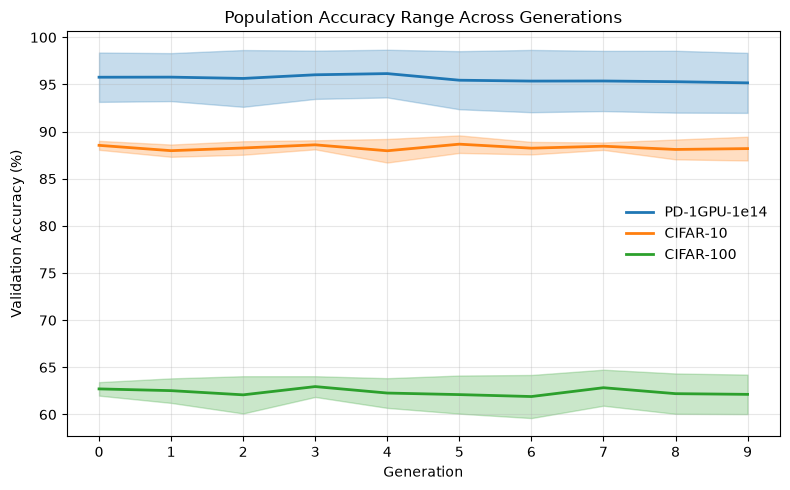

In [41]:
import numpy as np
import matplotlib.pyplot as plt

gen = np.arange(10)

# PD 1GPU 1e14
pd_min = [
    93.153187, 93.235072, 92.630385, 93.468128, 93.625598,
    92.372134, 92.057193, 92.176871, 92.013102, 91.987906
]

pd_max = [
    98.387503, 98.324515, 98.652053, 98.589065, 98.683547,
    98.532376, 98.664651, 98.563870, 98.576468, 98.356009
]

# CIFAR-10
c10_min = [
    88.07, 87.33, 87.55, 88.12, 86.72,
    87.74, 87.58, 88.06, 87.06, 86.94
]

c10_max = [
    89.02, 88.63, 88.98, 89.08, 89.22,
    89.60, 88.91, 88.85, 89.16, 89.46
]

# CIFAR-100
c100_min = [
    62.00, 61.23, 60.11, 61.86, 60.70,
    60.09, 59.62, 60.93, 60.07, 60.04
]

c100_max = [
    63.43, 63.83, 64.06, 64.06, 63.85,
    64.13, 64.19, 64.75, 64.35, 64.23
]

fig, ax = plt.subplots(figsize=(8, 5))

datasets = [
    ("PD-1GPU-1e14", pd_min, pd_max, "tab:blue"),
    ("CIFAR-10", c10_min, c10_max, "tab:orange"),
    ("CIFAR-100", c100_min, c100_max, "tab:green"),
]

for label, ymin, ymax, color in datasets:
    ymin = np.array(ymin)
    ymax = np.array(ymax)

    center = (ymin + ymax) / 2

    ax.plot(gen, center, color=color, lw=2, label=label)
    ax.fill_between(
        gen, ymin, ymax,
        color=color,
        alpha=0.25
    )

ax.set_xlabel("Generation")
ax.set_ylabel("Validation Accuracy (%)")
ax.set_xticks(gen)
ax.set_title("Population Accuracy Range Across Generations")
ax.legend(frameon=False)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

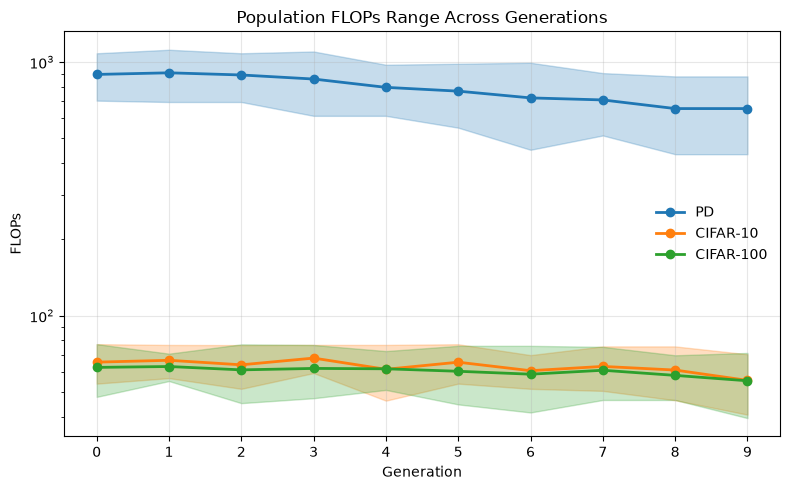

In [27]:
import numpy as np
import matplotlib.pyplot as plt

gen = np.arange(10)

# PD
pd_min = [
    704.3055, 695.5923, 695.5923, 613.4673, 613.4673,
    550.9177, 450.7927, 513.3423, 433.0796, 433.0796
]

pd_max = [
    1082.4730, 1117.7559, 1082.4730, 1100.1861, 975.4971,
    984.3537, 993.2103, 904.2344, 877.5212, 877.5212
]

# CIFAR-10
c10_min = [
    53.9682, 56.7350, 51.4862, 59.4013, 46.2374,
    53.9682, 51.4862, 50.5302, 46.4239, 40.7375
]

c10_max = [
    77.2142, 76.6705, 76.5507, 76.6958, 76.6958,
    77.1474, 69.8989, 75.6590, 75.6590, 70.4426
]

# CIFAR-100
c100_min = [
    47.8521, 55.2455, 45.2093, 47.2728, 50.9765,
    44.6909, 41.5380, 46.5195, 46.5195, 39.4745
]

c100_max = [
    77.2315, 70.8332, 77.0864, 76.6348, 72.5147,
    76.0496, 76.0496, 75.3445, 69.7964, 71.2848
]

fig, ax = plt.subplots(figsize=(8, 5))

datasets = [
    ("PD", pd_min, pd_max, "tab:blue"),
    ("CIFAR-10", c10_min, c10_max, "tab:orange"),
    ("CIFAR-100", c100_min, c100_max, "tab:green"),
]

for label, ymin, ymax, color in datasets:
    ymin = np.array(ymin)
    ymax = np.array(ymax)

    center = (ymin + ymax) / 2

    ax.plot(
        gen,
        center,
        color=color,
        lw=2,
        marker="o",
        label=label,
    )

    ax.fill_between(
        gen,
        ymin,
        ymax,
        color=color,
        alpha=0.25,
    )

ax.set_xlabel("Generation")
ax.set_ylabel("FLOPs")
ax.set_title("Population FLOPs Range Across Generations")
ax.set_xticks(gen)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
ax.set_yscale('log')

plt.tight_layout()
plt.show()

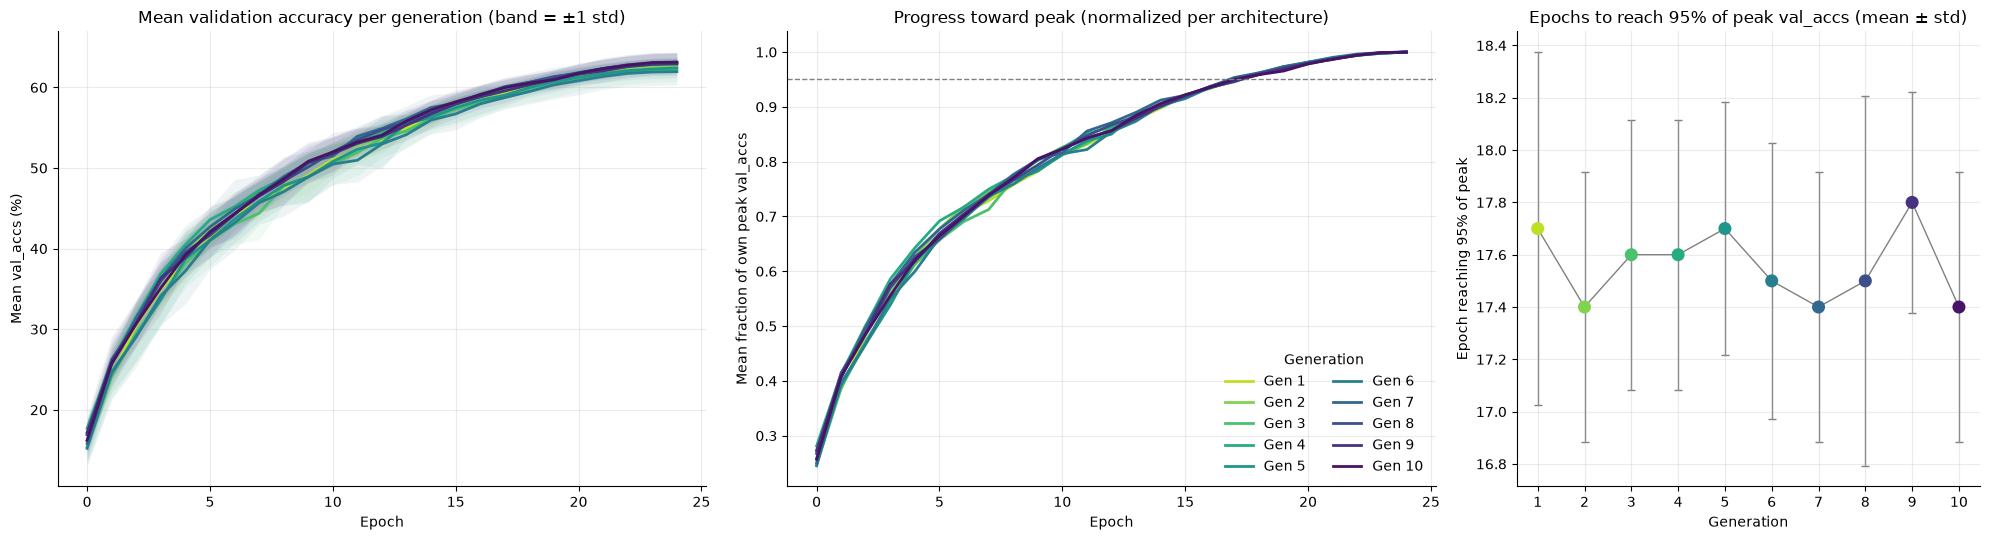

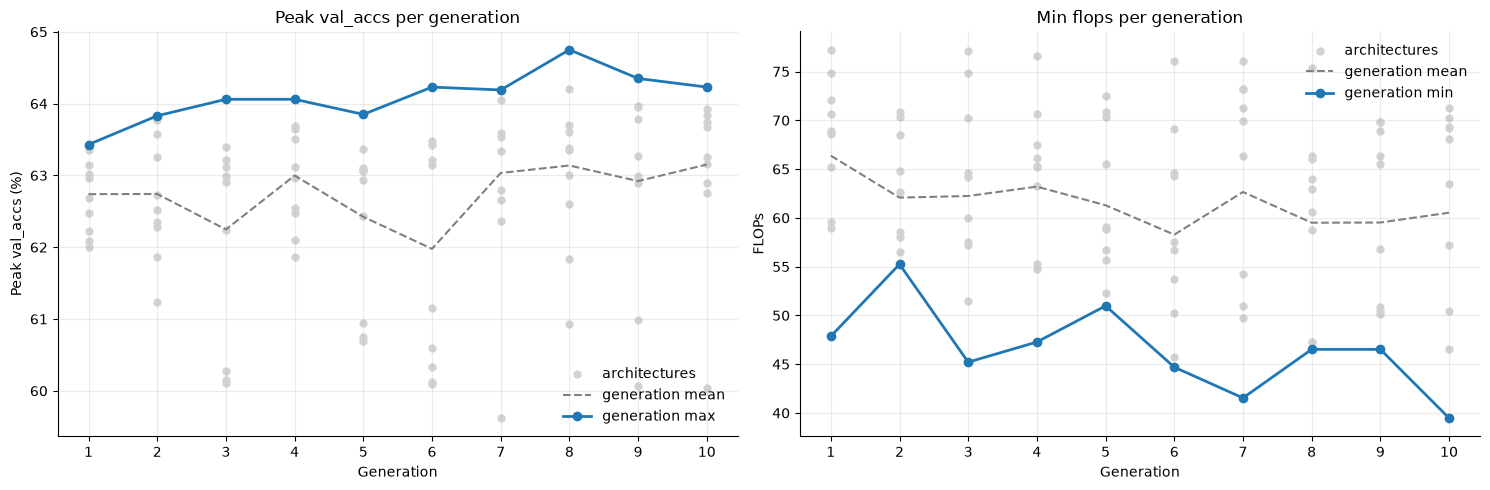

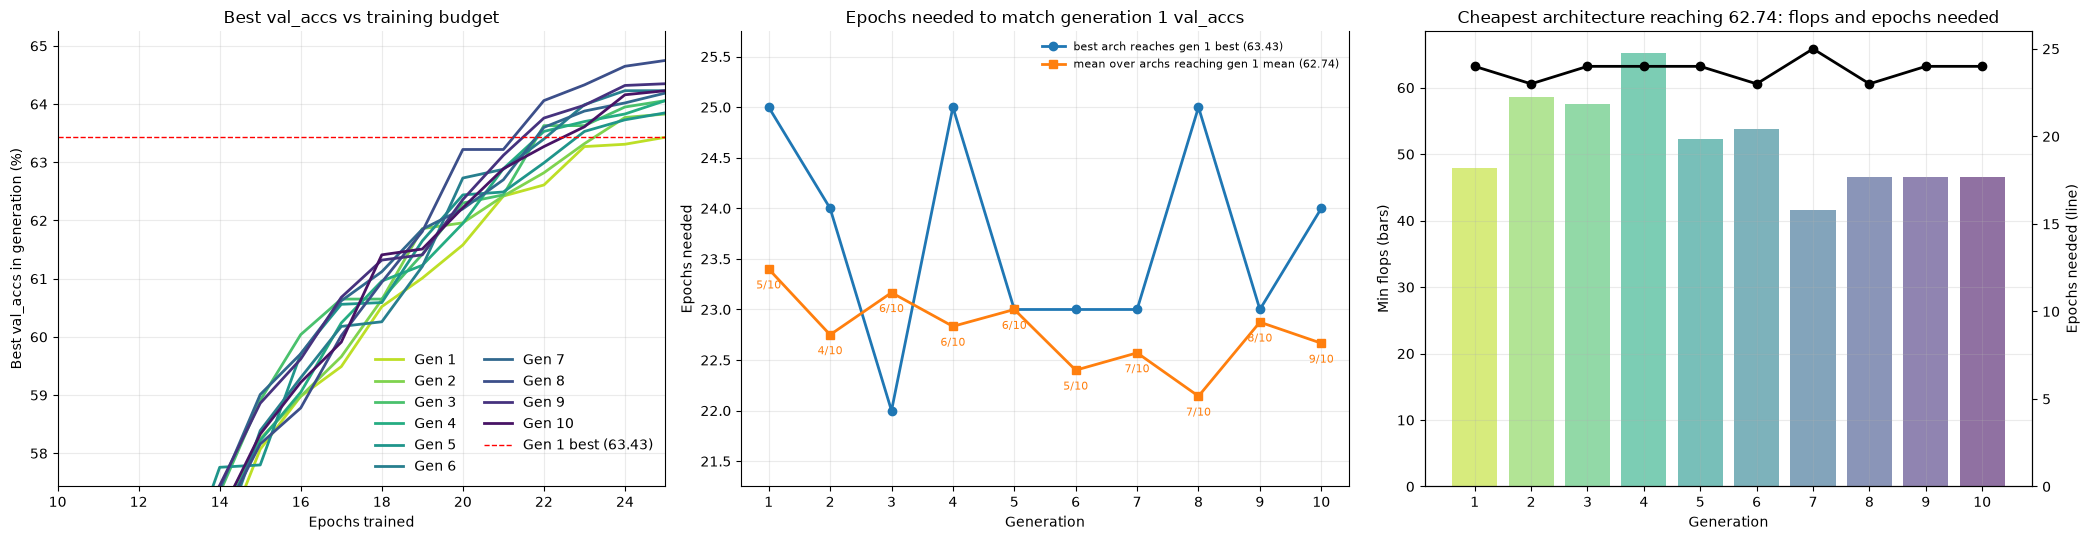

,epochs_to_gen1_best,n_reach_gen1_mean,epochs_to_gen1_mean,min_flops_at_gen1_mean,min_flops_epochs
generation,,,,,
1,25,5,23.40,47.85,24.0
2,24,4,22.75,58.57,23.0
3,22,6,23.17,57.54,24.0
4,25,6,22.83,65.22,24.0
5,23,6,23.00,52.25,24.0
6,23,5,22.40,53.76,23.0
7,23,7,22.57,41.54,25.0
8,25,7,22.14,46.52,23.0
9,23,8,22.88,46.52,24.0


In [17]:
# Learning curves per generation: mean val_accs across the architectures of each generation
curves = df[["arch", "epoch", "val_accs"]].copy()
curves["generation"] = curves["arch"].astype(int) // 10 + 1  # arch 0-9 -> gen 1, 10-19 -> gen 2, ...

gen_curves = curves.groupby(["generation", "epoch"])["val_accs"].agg(["mean", "std"]).reset_index()
generations = sorted(curves["generation"].unique())
cmap = plt.cm.viridis_r
colors = {g: cmap(0.1 + 0.85 * i / max(len(generations) - 1, 1)) for i, g in enumerate(generations)}

# Speed of convergence: first epoch at which an architecture reaches `peak_frac` of its own peak val_acc
peak_frac = 0.95
def epochs_to_peak(g):
    g = g.sort_values("epoch")
    return g.loc[g["val_accs"] >= peak_frac * g["val_accs"].max(), "epoch"].iloc[0]

per_arch = curves.groupby(["generation", "arch"]).apply(epochs_to_peak).rename("epoch_to_peak").reset_index()
per_arch["peak_val_acc"] = curves.groupby(["generation", "arch"])["val_accs"].max().values
gen_summary = per_arch.groupby("generation").agg(
    epoch_to_peak_mean=("epoch_to_peak", "mean"),
    epoch_to_peak_std=("epoch_to_peak", "std"),
    peak_val_acc_mean=("peak_val_acc", "mean"),
)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.4, 1.4, 1]})

# (1) raw mean learning curves, (2) same curves normalized by each architecture's peak
curves["frac_of_peak"] = curves["val_accs"] / curves.groupby("arch")["val_accs"].transform("max")
gen_frac = curves.groupby(["generation", "epoch"])["frac_of_peak"].mean().reset_index()

for g in generations:
    c = gen_curves[gen_curves["generation"] == g]
    axes[0].plot(c["epoch"], c["mean"], color=colors[g], lw=2, label=f"Gen {g}")
    axes[0].fill_between(c["epoch"], c["mean"] - c["std"], c["mean"] + c["std"], color=colors[g], alpha=0.08, lw=0)
    f = gen_frac[gen_frac["generation"] == g]
    axes[1].plot(f["epoch"], f["frac_of_peak"], color=colors[g], lw=2, label=f"Gen {g}")

axes[0].set(xlabel="Epoch", ylabel="Mean val_accs (%)", title="Mean validation accuracy per generation (band = ±1 std)")
axes[1].axhline(peak_frac, color="gray", ls="--", lw=1)
axes[1].set(xlabel="Epoch", ylabel="Mean fraction of own peak val_accs", title="Progress toward peak (normalized per architecture)")
axes[1].legend(title="Generation", ncol=2, frameon=False, loc="lower right")

# (3) epochs needed to reach peak_frac of peak, per generation
axes[2].errorbar(gen_summary.index, gen_summary["epoch_to_peak_mean"], yerr=gen_summary["epoch_to_peak_std"],
                 color="gray", lw=1, capsize=3, zorder=1)
axes[2].scatter(gen_summary.index, gen_summary["epoch_to_peak_mean"], c=[colors[g] for g in gen_summary.index], s=70, zorder=2)
axes[2].set(xlabel="Generation", ylabel=f"Epoch reaching {peak_frac:.0%} of peak",
            title=f"Epochs to reach {peak_frac:.0%} of peak val_accs (mean ± std)", xticks=generations)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

gen_summary.round(2)

#Best of each generation: peak val_accs (higher is better) and min flops (lower is better)
arch_stats = df.groupby("arch").agg(peak_val_acc=("val_accs", "max"), flops=("flops", "first")).reset_index()
arch_stats["generation"] = arch_stats["arch"].astype(int) // 10 + 1  # arch 0-9 -> gen 1, 10-19 -> gen 2, ...

gen_best = arch_stats.groupby("generation").agg(
    peak_val_acc=("peak_val_acc", "max"),
    mean_val_acc=("peak_val_acc", "mean"),
    min_flops=("flops", "min"),
    mean_flops=("flops", "mean"),
)
# flops of the most accurate architecture, and accuracy of the cheapest one, in each generation
gen_best["flops_of_best_acc"] = arch_stats.loc[arch_stats.groupby("generation")["peak_val_acc"].idxmax()].set_index("generation")["flops"]
gen_best["val_acc_of_min_flops"] = arch_stats.loc[arch_stats.groupby("generation")["flops"].idxmin()].set_index("generation")["peak_val_acc"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
panels = [
    ("peak_val_acc", "peak_val_acc", "mean_val_acc", "Peak val_accs (%)", "Peak val_accs per generation", "max"),
    ("flops", "min_flops", "mean_flops", "FLOPs", "Min flops per generation", "min"),
]
for ax, (col, best, mean, ylabel, title, kind) in zip(axes, panels):
    ax.scatter(arch_stats["generation"], arch_stats[col], color="lightgray", s=25, label="architectures")
    ax.plot(gen_best.index, gen_best[mean], color="gray", ls="--", lw=1.5, label="generation mean")
    ax.plot(gen_best.index, gen_best[best], color="tab:blue", marker="o", lw=2, label=f"generation {kind}")
    ax.set(xlabel="Generation", ylabel=ylabel, title=title, xticks=gen_best.index)
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

gen_best.round(2)
# Training epochs needed per generation to match generation 1 (every architecture is trained for the same number of epochs,
# so we ask: at which epoch could training have stopped and still matched generation 1's final result?)
ep = df[["arch", "epoch", "val_accs", "flops"]].sort_values(["arch", "epoch"]).copy()
ep["generation"] = ep["arch"].astype(int) // 10 + 1  # arch 0-9 -> gen 1, 10-19 -> gen 2, ...
ep["n_epochs"] = ep["epoch"] + 1                      # epochs trained so far
ep["best_so_far"] = ep.groupby("arch")["val_accs"].cummax()
gens = sorted(ep["generation"].unique())
cmap = plt.cm.viridis_r
gen_colors = {g: cmap(0.1 + 0.85 * i / max(len(gens) - 1, 1)) for i, g in enumerate(gens)}

def epochs_to_reach(g, target):
    """Number of epochs after which val_accs first reaches `target` (NaN if never)."""
    hit = g.loc[g["val_accs"] >= target, "n_epochs"]
    return hit.iloc[0] if len(hit) else np.nan

arch_peak = ep.groupby("arch")["val_accs"].max()
gen_of = ep.groupby("arch")["generation"].first()
flops_of = ep.groupby("arch")["flops"].first()
# Targets set by generation 1
target_best = arch_peak[gen_of == 1].max()            # best architecture of gen 1
target_mean = arch_peak[gen_of == 1].mean()           # average architecture of gen 1

to_mean = ep.groupby("arch").apply(epochs_to_reach, target=target_mean)
epoch_summary = pd.DataFrame({
    # earliest epoch at which any architecture of the generation matches gen 1's best
    "epochs_to_gen1_best": ep.groupby("generation").apply(epochs_to_reach, target=target_best),
    # architectures reaching gen 1's mean peak, and how many epochs they need on average
    "n_reach_gen1_mean": to_mean.notna().groupby(gen_of).sum(),
    "epochs_to_gen1_mean": to_mean.groupby(gen_of).mean(),
})
# cheapest architecture of each generation that still reaches gen 1's mean peak, and the epochs it needs to get there
good = to_mean.dropna().index
cheapest_good = flops_of[good].groupby(gen_of[good]).idxmin()
epoch_summary["min_flops_at_gen1_mean"] = flops_of[cheapest_good].values
epoch_summary["min_flops_epochs"] = to_mean[cheapest_good].values
epoch_summary.index.name = "generation"

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

# (1) best val_accs reached by any architecture of the generation, as a function of training budget
gen_best_curve = ep.groupby(["generation", "n_epochs"])["best_so_far"].max().reset_index()
for g in gens:
    c = gen_best_curve[gen_best_curve["generation"] == g]
    axes[0].plot(c["n_epochs"], c["best_so_far"], color=gen_colors[g], lw=2, label=f"Gen {g}")
axes[0].axhline(target_best, color="red", ls="--", lw=1, label=f"Gen 1 best ({target_best:.2f})")
axes[0].set(xlabel="Epochs trained", ylabel="Best val_accs in generation (%)", xlim=(10, ep["n_epochs"].max()),
            ylim=(target_best - 6, arch_peak.max() + 0.5), title="Best val_accs vs training budget")
axes[0].legend(ncol=2, frameon=False, loc="lower right")

# (2) epochs needed to match generation 1
axes[1].plot(epoch_summary.index, epoch_summary["epochs_to_gen1_best"], marker="o", lw=2, color="tab:blue",
             label=f"best arch reaches gen 1 best ({target_best:.2f})")
axes[1].plot(epoch_summary.index, epoch_summary["epochs_to_gen1_mean"], marker="s", lw=2, color="tab:orange",
             label=f"mean over archs reaching gen 1 mean ({target_mean:.2f})")
for g, n in epoch_summary["n_reach_gen1_mean"].items():
    axes[1].annotate(f"{n}/10", (g, epoch_summary.loc[g, "epochs_to_gen1_mean"]), textcoords="offset points",
                     xytext=(0, -14), ha="center", fontsize=8, color="tab:orange")
axes[1].set(xlabel="Generation", ylabel="Epochs needed", xticks=gens, title="Epochs needed to match generation 1 val_accs")
axes[1].margins(y=0.25)
axes[1].legend(frameon=False, loc="upper right", fontsize=8)

# (3) cheapest architecture that still reaches gen 1's mean peak: its flops (bars) and the epochs it needs (line)
axes[2].bar(epoch_summary.index, epoch_summary["min_flops_at_gen1_mean"], color=[gen_colors[g] for g in gens], alpha=0.6)
axes[2].set(xlabel="Generation", ylabel="Min flops (bars)", xticks=gens,
            title=f"Cheapest architecture reaching {target_mean:.2f}: flops and epochs needed")
ax2 = axes[2].twinx()
ax2.plot(epoch_summary.index, epoch_summary["min_flops_epochs"], color="black", marker="o", lw=2)
ax2.set(ylabel="Epochs needed (line)", ylim=(0, ep["n_epochs"].max() + 1))

for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[["top"]].set_visible(False)
plt.tight_layout()
plt.show()

epoch_summary.round(2)